# TradeSense · Component 03 · TGNN · Stage C — EDA, preprocessing and causal graph-feature build (v1.1)

**v1.1 change:** one extra node channel `dist_slog` (signed log of the distance from mid) because the real v1 run showed that `dist_ticks` alone is dominated by far levels (scaler std 308). Everything else is unchanged. It writes a NEW folder (`..._v2`); your v1 folder is not touched.

**What this notebook does.** It reads the **12 audited Tardis order-book datasets** (BTCUSDT and ETHUSDT, 2024-05-01 … 2024-10-01) that are already in your Drive, and turns each day into a causal sequence of **order-book graphs**: 25 bid nodes + 25 ask nodes + 1 global node, one graph every **100 ms**, 50 graphs (= 5 s) per training window, target = the **next** 100 ms interval.
It does the EDA on the **training days only**, fits the scaler on the **training days only**, freezes it, and applies it unchanged to validation and test days. Then it runs the PASS/FAIL tests and gives a **TGNN training-readiness decision**.

**What it does NOT do.** No download. No model training (no TGNN, no baselines). No fusion, no lifecycle. It never writes to the audited folders or to any frozen Autoencoder / XGBoost / Transformer artefact — everything goes into a **new versioned folder** `TGNN_StageC_GraphFeatures_vN` in your Drive.

**Splits (frozen, Protocol v2).** Train: 2024-05-01 + 2024-06-01 · Validation: 2024-07-01 · Test: 2024-08-01 + 2024-09-01 + 2024-10-01 · both symbols. Test days are **not used** for any design decision here (EDA, scaler, thresholds, readiness rules use training days only; test days are only processed with the frozen settings and described afterwards).

**Features are BOOK-ONLY.** The trade files are never opened. Nothing derived from trades enters any feature or target.

**Honest limits.** (1) The reconstructed book is *consistent with Tardis's own `book_snapshot_25`* — that is the same feed, not independent validation. (2) The resource benchmark at the end uses a small **stand-in network** (forward + backward on real tensors, no optimiser step, weights discarded) — it measures cost, it does not learn anything and is not the TGNN. (3) Nothing here detects or proves manipulation, spoofing or layering.

**If Colab disconnects:** set `RESUME_DIR` in cell 1 to the folder name printed in cell 3 and press *Run all* — finished days are skipped, nothing finished is overwritten.

## 1 · Settings (the only cell you may need to edit)

In [ ]:
import os, gc, sys, json, time, shutil, traceback, hashlib, tempfile, pickle, platform, random
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab -> using TRADESENSE_BASE.')
BASE = Path(os.environ.get('TRADESENSE_BASE', '/content/drive/MyDrive/research datasets')); assert BASE.is_dir(), f'Drive folder not found: {BASE}'
SYMS = ['BTCUSDT', 'ETHUSDT']
SPLITS = {'train': ['2024-05-01', '2024-06-01'], 'val': ['2024-07-01'], 'test': ['2024-08-01', '2024-09-01', '2024-10-01']}      # frozen by Protocol v2
RESUME_DIR = None            # e.g. 'TGNN_StageC_GraphFeatures_v1' to continue an unfinished run; None = start a new versioned folder
N_WORKERS = 2                # days processed in parallel (each day needs about 2-3 GB RAM; use 1 if Colab says "out of memory")
RUN_REGEN_TEST = True        # re-build one training day from scratch and compare hashes (costs one extra day of compute)
WORKDIR = Path('/content') if Path('/content').exists() else Path(os.getcwd())
SCRATCH = WORKDIR / 'stagec_scratch'      # local, disposable (100 ms book levels of the training days); not Drive
# ---- decision thresholds, fixed BEFORE looking at any result (they use training data only) ----
SNAP_MIN_SHARE = 0.95        # share of comparable intervals whose top-25 equals the provider's book_snapshot_25 (price and quantity)
RANK_RISK_SHARE = 0.25       # if more than this share of node slots change their price level between consecutive valid 100 ms intervals -> "READY WITH RISK" (rank identity is unstable)
MAX_EPOCH_MIN = 120          # stand-in forward+backward over ALL training windows must fit in this many minutes on this machine
MAX_RAM_FRAC = 0.85          # peak RAM of any worker / total RAM
STORAGE_MARGIN = 1.10        # Drive free space must exceed the tensors written * this
SETS = [(sym, day, split) for split in ('train', 'val', 'test') for day in SPLITS[split] for sym in SYMS]
def sdir(sym, day): return BASE / f'TGNN_Tardis_Binance_Spot_{sym}_{day}_v1'
print('sets:', len(SETS)); [print('  ', split, sym, day, '->', 'found' if sdir(sym, day).is_dir() else 'MISSING') for sym, day, split in SETS]

Mounted at /content/drive
sets: 12
   train BTCUSDT 2024-05-01 -> found
   train ETHUSDT 2024-05-01 -> found
   train BTCUSDT 2024-06-01 -> found
   train ETHUSDT 2024-06-01 -> found
   val BTCUSDT 2024-07-01 -> found
   val ETHUSDT 2024-07-01 -> found
   test BTCUSDT 2024-08-01 -> found
   test ETHUSDT 2024-08-01 -> found
   test BTCUSDT 2024-09-01 -> found
   test ETHUSDT 2024-09-01 -> found
   test BTCUSDT 2024-10-01 -> found
   test ETHUSDT 2024-10-01 -> found


[None, None, None, None, None, None, None, None, None, None, None, None]

## 2 · The feature library (written to the Colab working folder, not to Drive)

Causal replay of the order book onto the 100 ms grid, flags, features, scaler, tensor writer, checks. Nothing runs here; it only saves `stagec_lib.py`. You do not need to read it.

In [ ]:
%%writefile stagec_lib.py
# TradeSense · TGNN · Stage C library (read-only feature build). Written to the Colab working folder by notebook 13.
# Everything here is CAUSAL: the state of interval k uses only book rows with local_timestamp < end of interval k.
import os, gc, json, time, math, hashlib, resource
from bisect import bisect_left, insort
from pathlib import Path
import numpy as np
import pyarrow as pa, pyarrow.csv as pacsv

K = 25; STEP_US = 100_000; DAY_US = 86_400_000_000; N_INT = DAY_US // STEP_US          # 864,000 intervals of 100 ms per UTC day
SEQ = 50; WARMUP_INT = 600; STALE_RUN = 10; INTERVALS_PER_MINUTE = 600
NODE_FEATS = ['side', 'dist_ticks', 'log_qty', 'd_log_qty', 'cum_log_depth', 'dist_slog']
GLOB_FEATS = ['log_spread_ticks', 'imbalance_top5', 'mid_change_signed_log']
SCALED_NODE = [1, 2, 3, 4, 5]; SIDE = np.array([-1.0] * K + [1.0] * K)
FLAG_NO_STATE, FLAG_SHORT, FLAG_CROSSED, FLAG_STALE, FLAG_WARMUP = 1, 2, 4, 8, 16
FLAG_NAMES = {1: 'NO_STATE', 2: 'SHORT_SIDE', 4: 'CROSSED_OR_LOCKED', 8: 'STALE_GAP', 16: 'WARMUP'}
F16_LIM = 60000.0

def sha256_file(p, chunk=16 << 20):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()
def peak_gb(): return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
def jsonable(o):
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (Path,)): return str(o)
    return str(o)
def dump_json(obj, path):
    tmp = str(path) + '.tmp'; Path(tmp).write_text(json.dumps(obj, indent=1, default=jsonable)); os.replace(tmp, path)

# ----------------------------------------------------------------------------- reading
_BOOK_COLS = ['local_timestamp', 'is_snapshot', 'side', 'price', 'amount']
def open_book(path, block_mb=48):
    ro = pacsv.ReadOptions(block_size=block_mb << 20)
    co = pacsv.ConvertOptions(include_columns=_BOOK_COLS, column_types={'local_timestamp': pa.int64(), 'is_snapshot': pa.bool_(), 'side': pa.string(), 'price': pa.float64(), 'amount': pa.float64()}, strings_can_be_null=False, true_values=['true', 'True', 'TRUE'], false_values=['false', 'False', 'FALSE'])
    return pacsv.open_csv(str(path), read_options=ro, convert_options=co)

def tick_infer(book_path, n_rows=2_000_000):
    """largest 'nice' step (1, 2 or 5 x 10^k) on which every price of the first rows lies"""
    rd = open_book(book_path, 16); ps = []; n = 0
    for b in rd:
        ps.append(np.unique(b.column('price').to_numpy(zero_copy_only=False))); n += b.num_rows
        if n >= n_rows: break
    p = np.unique(np.concatenate(ps))
    for c in sorted({m * 10.0 ** k for m in (1, 2, 5) for k in range(-8, 3)}, reverse=True):
        r = p / c
        if np.all(np.abs(r - np.rint(r)) < 1e-4): return c
    raise RuntimeError('no tick size found')

# ----------------------------------------------------------------------------- causal replay onto the 100 ms grid
def replay_day(book_path, day0_us, tick, n_int=N_INT, max_rows=None, verbose=True, label=''):
    """S_k = book after applying ALL rows with local_timestamp < day0 + (k+1)*100 ms (a row exactly on a boundary belongs to the NEXT interval).
    Rows before the first snapshot are skipped; a snapshot batch resets the book (same rules as the audit notebooks). Full depth, never pruned."""
    t0 = time.time()
    L = {k: np.zeros((n_int, K), d) for k, d in (('bid_px', np.int32), ('bid_q', np.float32), ('ask_px', np.int32), ('ask_q', np.float32))}
    L.update(nbid=np.zeros(n_int, np.int32), nask=np.zeros(n_int, np.int32), n_msgs=np.zeros(n_int, np.int32), n_rows=np.zeros(n_int, np.int32), last_L=np.zeros(n_int, np.int64))
    bid_px, bid_q, ask_px, ask_q, nbid, nask = L['bid_px'], L['bid_q'], L['ask_px'], L['ask_q'], L['nbid'], L['nask']
    bd, ad, bl, al = {}, {}, [], []        # bl = NEGATED bid ticks ascending (best bid first); al = ask ticks ascending (best ask first)
    st = dict(rows=0, raw_rows=0, dropped_invalid_rows=0, rows_before_day=0, rows_after_day=0, skipped_pre=0, off_grid_rows=0, resets=0, local_inversions=0)
    started = False; pf = None; next_emit = 0; done = False; c_started = False; c_F = False; c_L = -1; prev_row_L = None; nrep = 0
    def extract_into(a, b):
        if b <= a: return
        kb = min(K, len(bl)); ka = min(K, len(al))
        if kb: pk = [-x for x in bl[:kb]]; bid_px[a:b, :kb] = pk; bid_q[a:b, :kb] = [bd[x] for x in pk]
        if ka: pk = al[:ka]; ask_px[a:b, :ka] = pk; ask_q[a:b, :ka] = [ad[x] for x in pk]
        nbid[a:b] = len(bl); nask[a:b] = len(al)
    for b in open_book(book_path):
        Ls = b.column('local_timestamp').to_numpy(zero_copy_only=False); m = len(Ls)
        if max_rows is not None:
            rem = max_rows - st['rows']
            if rem <= 0: break
            if m > rem: b = b.slice(0, rem); Ls = Ls[:rem]; m = rem
        _px = b.column('price').to_numpy(zero_copy_only=False); _am = b.column('amount').to_numpy(zero_copy_only=False)
        _keep = np.isfinite(_px) & (_px > 0) & np.isfinite(_am) & (_am >= 0); st['raw_rows'] += m
        if not _keep.all():                                                                    # documented rule: a row with a non-finite/non-positive price or a non-finite/negative amount is DROPPED and counted (never repaired, never filled)
            st['dropped_invalid_rows'] += int((~_keep).sum()); b = b.filter(pa.array(_keep)); Ls = b.column('local_timestamp').to_numpy(zero_copy_only=False); m = len(Ls)
            if m == 0: continue
        Fs = b.column('is_snapshot').to_numpy(zero_copy_only=False).astype(bool); Bs = (b.column('side').to_numpy(zero_copy_only=False) == 'bid'); Px = b.column('price').to_numpy(zero_copy_only=False); Am = b.column('amount').to_numpy(zero_copy_only=False)
        inv = int((np.diff(Ls) < 0).sum()) + (1 if prev_row_L is not None and Ls[0] < prev_row_L else 0); st['local_inversions'] += inv
        if inv: raise ValueError(f'{label}: local_timestamp is not non-decreasing ({inv} inversions): the causal grid is undefined, stop and report')
        prev_row_L = int(Ls[-1]); st['rows'] += m
        Pt = np.rint(Px / tick).astype(np.int64); st['off_grid_rows'] += int((np.abs(Px / tick - Pt) > 1e-4).sum())
        k_row = (Ls - day0_us) // STEP_US; inr = (k_row >= 0) & (k_row < n_int); st['rows_before_day'] += int((k_row < 0).sum()); st['rows_after_day'] += int((k_row >= n_int).sum())
        Pl, Al, Bl, Fl = Pt.tolist(), Am.tolist(), Bs.tolist(), Fs.tolist(); fcum = np.concatenate([[0], np.cumsum(Fs)])
        cuts = np.flatnonzero(k_row[1:] != k_row[:-1]) + 1; starts = np.concatenate([[0], cuts]).tolist(); ends = np.concatenate([cuts, [m]]).tolist(); kks = k_row[np.array(starts)].tolist()
        snapc = np.maximum.accumulate(Fs); st_row = snapc | c_started
        for s, e, kk in zip(starts, ends, kks):
            if kk >= n_int: done = True; break
            if kk >= 0 and kk > next_emit: extract_into(next_emit, kk); next_emit = kk
            if started and fcum[e] - fcum[s] == 0:
                for i in range(s, e):
                    p = Pl[i]; a = Al[i]
                    if Bl[i]:
                        if a > 0:
                            if p not in bd: insort(bl, -p)
                            bd[p] = a
                        elif p in bd: del bd[p]; del bl[bisect_left(bl, -p)]
                    else:
                        if a > 0:
                            if p not in ad: insort(al, p)
                            ad[p] = a
                        elif p in ad: del ad[p]; del al[bisect_left(al, p)]
                pf = False
            else:
                for i in range(s, e):
                    f = Fl[i]
                    if not started:
                        if not f: st['skipped_pre'] += 1; pf = f; continue
                        started = True
                    if f and not pf: bd.clear(); ad.clear(); bl.clear(); al.clear(); st['resets'] += 1
                    p = Pl[i]; a = Al[i]
                    if Bl[i]:
                        if a > 0:
                            if p not in bd: insort(bl, -p)
                            bd[p] = a
                        elif p in bd: del bd[p]; del bl[bisect_left(bl, -p)]
                    else:
                        if a > 0:
                            if p not in ad: insort(al, p)
                            ad[p] = a
                        elif p in ad: del ad[p]; del al[bisect_left(al, p)]
                    pf = f
            if 0 <= kk < n_int and st_row[e - 1]: L['last_L'][kk] = Ls[e - 1]
        # vectorised per-interval counters (rows, messages)
        L['n_rows'] += np.bincount(k_row[inr], minlength=n_int).astype(np.int32)
        first_started = st_row & ~np.concatenate([[c_started], st_row[:-1]]); prevF = np.concatenate([[c_F], Fs[:-1]]); prevL = np.concatenate([[c_L], Ls[:-1]])
        msg_start = st_row & (first_started | (Fs != prevF) | (~Fs & (Ls != prevL)))
        L['n_msgs'] += np.bincount(k_row[msg_start & inr], minlength=n_int).astype(np.int32)
        c_started = bool(st_row[-1]); c_F = bool(Fs[-1]); c_L = int(Ls[-1])
        if verbose and st['rows'] // 10_000_000 != nrep: nrep = st['rows'] // 10_000_000; print(f'   {label} replayed {st["rows"]:,} rows | {time.time()-t0:.0f}s')
        if done: break
    extract_into(next_emit, n_int)
    st.update(messages=int(L['n_msgs'].sum()), final_levels=(len(bl), len(al)), seconds=round(time.time() - t0, 1), peak_rss_gb=round(peak_gb(), 2))
    return L, st

# ----------------------------------------------------------------------------- flags, windows, features
def make_flags(lv, warmup=WARMUP_INT, stale_run=STALE_RUN):
    n = len(lv['nbid']); nb, na = lv['nbid'], lv['nask']
    no_state = (nb == 0) | (na == 0); short = (~no_state) & ((nb < K) | (na < K)); crossed = (~no_state) & (lv['bid_px'][:, 0] >= lv['ask_px'][:, 0])
    z = lv['n_msgs'] == 0; idx = np.arange(n); last_nz = np.maximum.accumulate(np.where(~z, idx, -1)); stale = z & ((idx - last_nz) >= stale_run)      # run of silent intervals counted UP TO k only (causal)
    started = np.flatnonzero(~no_state); k0 = int(started[0]) if len(started) else n; warm = idx < (k0 + warmup)
    return (no_state * FLAG_NO_STATE + short * FLAG_SHORT + crossed * FLAG_CROSSED + stale * FLAG_STALE + warm * FLAG_WARMUP).astype(np.uint8)
def eligible_windows(flags, seq=SEQ):
    """end index t of every window whose intervals t-seq .. t+1 are all flag-free (t-seq is needed for the first quantity change; t+1 is the target)"""
    n = len(flags); c = np.concatenate([[0], np.cumsum((flags != 0).astype(np.int64))]); t = np.arange(seq, n - 1)
    return t[(c[t + 2] - c[t - seq]) == 0].astype(np.int32)
def raw_features(lv, a, b):
    """unscaled features of intervals [a, b); interval a-1 is read only for the two 'change' features (causal: nothing after b-1 is touched)"""
    lo = max(a - 1, 0); sl = slice(lo, b)
    bp = lv['bid_px'][sl].astype(np.float64); ap = lv['ask_px'][sl].astype(np.float64); bq = lv['bid_q'][sl].astype(np.float64); aq = lv['ask_q'][sl].astype(np.float64)
    mid = (bp[:, 0] + ap[:, 0]) / 2.0; dist = np.concatenate([bp - mid[:, None], ap - mid[:, None]], 1)
    lq = np.log1p(np.concatenate([bq, aq], 1)); cum = np.concatenate([np.log1p(np.cumsum(bq, 1)), np.log1p(np.cumsum(aq, 1))], 1)
    dlq = np.zeros_like(lq); dlq[1:] = lq[1:] - lq[:-1]
    sp = np.log1p(np.maximum(ap[:, 0] - bp[:, 0], 0)); s5b = bq[:, :5].sum(1); s5a = aq[:, :5].sum(1); imb = (s5b - s5a) / np.maximum(s5b + s5a, 1e-12)
    dm = np.zeros(len(mid)); dm[1:] = mid[1:] - mid[:-1]; smc = np.sign(dm) * np.log1p(np.abs(dm)); off = a - lo
    node = np.stack([np.broadcast_to(SIDE, dist.shape), dist, lq, dlq, cum, np.sign(dist) * np.log1p(np.abs(dist))], -1)[off:]; glob = np.stack([sp, imb, smc], -1)[off:]
    return node, glob
def feature_scalar(lv, k):
    """independent pure-python recomputation of ONE interval (used only to check the vectorised code); returns node (50,5), glob (3,) raw"""
    def side_rows(px, q): return [(float(px[k, r]), float(q[k, r])) for r in range(K)]
    B = side_rows(lv['bid_px'], lv['bid_q']); A = side_rows(lv['ask_px'], lv['ask_q'])
    def prev(px, q, r): return float(q[k - 1, r]) if k > 0 else None
    mid = (B[0][0] + A[0][0]) / 2.0; mid_prev = (float(lv['bid_px'][k - 1, 0]) + float(lv['ask_px'][k - 1, 0])) / 2.0 if k > 0 else mid
    node = []
    for side, rows, px, q in ((-1.0, B, lv['bid_px'], lv['bid_q']), (1.0, A, lv['ask_px'], lv['ask_q'])):
        cum = 0.0
        for r, (p, qq) in enumerate(rows):
            cum += qq; pq = prev(px, q, r); dl = (math.log1p(qq) - math.log1p(pq)) if pq is not None else 0.0
            node.append([side, p - mid, math.log1p(qq), dl, math.log1p(cum), math.copysign(math.log1p(abs(p - mid)), p - mid) if p != mid else 0.0])
    s5b = sum(x[1] for x in B[:5]); s5a = sum(x[1] for x in A[:5]); dm = mid - mid_prev
    glob = [math.log1p(max(A[0][0] - B[0][0], 0.0)), (s5b - s5a) / max(s5b + s5a, 1e-12), math.copysign(math.log1p(abs(dm)), dm) if dm != 0 else 0.0]
    return np.array(node), np.array(glob)

# ----------------------------------------------------------------------------- scaler (fitted on TRAINING days only; Chan/Welford merge)
class Moments:
    def __init__(s, n_ch): s.n = 0; s.mean = np.zeros(n_ch); s.m2 = np.zeros(n_ch)
    def add(s, x):                                  # x: (rows, n_ch) float64
        if len(x) == 0: return
        n2 = len(x); m2_ = x.mean(0); M2 = ((x - m2_) ** 2).sum(0); n1 = s.n; n = n1 + n2; d = m2_ - s.mean
        s.mean = s.mean + d * n2 / n; s.m2 = s.m2 + M2 + d ** 2 * n1 * n2 / n; s.n = n
    def std(s): return np.sqrt(s.m2 / max(s.n, 1))
def scaler_accumulate(lv, flags, mom_node, mom_glob, chunk=50_000):
    n = len(flags); good = (flags == 0); ok = good.copy(); ok[1:] &= good[:-1]; ok[0] = False
    for a in range(0, n, chunk):
        b = min(a + chunk, n)
        if not ok[a:b].any(): continue
        node, glob = raw_features(lv, a, b); m = ok[a:b]
        x = node[m][:, :, SCALED_NODE].reshape(-1, len(SCALED_NODE)); mom_node.add(x.astype(np.float64)); mom_glob.add(glob[m].astype(np.float64))
def scaler_from_moments(mom_node, mom_glob, floor=1e-8):
    sn = mom_node.std(); sg = mom_glob.std(); flags = {'node_std_floored': [int(x < floor) for x in sn], 'glob_std_floored': [int(x < floor) for x in sg]}
    return {'node_channels': [NODE_FEATS[i] for i in SCALED_NODE], 'node_mean': mom_node.mean.tolist(), 'node_std': np.where(sn < floor, 1.0, sn).tolist(), 'glob_channels': GLOB_FEATS, 'glob_mean': mom_glob.mean.tolist(), 'glob_std': np.where(sg < floor, 1.0, sg).tolist(), 'n_node_values': int(mom_node.n), 'n_glob_values': int(mom_glob.n), **flags}
def apply_scaler(node, glob, flags_chunk, sc):
    node = node.copy(); glob = glob.copy()
    for j, ch in enumerate(SCALED_NODE): node[:, :, ch] = (node[:, :, ch] - sc['node_mean'][j]) / sc['node_std'][j]
    glob = (glob - np.array(sc['glob_mean'])) / np.array(sc['glob_std'])
    inval = (flags_chunk & (FLAG_NO_STATE | FLAG_SHORT)) != 0; node[inval, :, 1:] = 0.0; glob[inval] = 0.0     # structural placeholder, never used by an eligible window
    return node, glob

# ----------------------------------------------------------------------------- tensors
def build_tensors(lv, flags, sc, out_dir, chunk=50_000):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True); n = len(flags)
    nodes = np.lib.format.open_memmap(out_dir / 'nodes.npy', mode='w+', dtype=np.float16, shape=(n, 2 * K, len(NODE_FEATS))); glob_ = np.zeros((n, len(GLOB_FEATS)), np.float16)
    stats = {'abs_max_node': [0.0] * len(NODE_FEATS), 'abs_max_glob': [0.0] * len(GLOB_FEATS), 'n_gt10': 0, 'n_gt100': 0, 'f16_clipped_values': 0, 'nonfinite_before_cast': 0}
    for a in range(0, n, chunk):
        b = min(a + chunk, n); node, gl = raw_features(lv, a, b); node, gl = apply_scaler(node, gl, flags[a:b], sc)
        stats['nonfinite_before_cast'] += int((~np.isfinite(node)).sum() + (~np.isfinite(gl)).sum())
        stats['f16_clipped_values'] += int((np.abs(node) > F16_LIM).sum() + (np.abs(gl) > F16_LIM).sum())
        stats['n_gt10'] += int((np.abs(node[:, :, 1:]) > 10).sum()); stats['n_gt100'] += int((np.abs(node[:, :, 1:]) > 100).sum())
        for c in range(len(NODE_FEATS)): stats['abs_max_node'][c] = max(stats['abs_max_node'][c], float(np.abs(node[:, :, c]).max()))
        for c in range(len(GLOB_FEATS)): stats['abs_max_glob'][c] = max(stats['abs_max_glob'][c], float(np.abs(gl[:, c]).max()))
        nodes[a:b] = np.clip(node, -F16_LIM, F16_LIM).astype(np.float16); glob_[a:b] = np.clip(gl, -F16_LIM, F16_LIM).astype(np.float16)
    nodes.flush(); del nodes
    np.save(out_dir / 'glob.npy', glob_); np.save(out_dir / 'flags.npy', flags); np.save(out_dir / 'n_msgs.npy', lv['n_msgs'].astype(np.int16)); win = eligible_windows(flags); np.save(out_dir / 'win_end.npy', win)
    return win, stats

# ----------------------------------------------------------------------------- provider snapshot cross-check
def compare_snapshots(lv, flags, snap_path, day0_us, tick):
    """intervals whose LAST message has exactly the local_timestamp of a provider book_snapshot_25 row must show the same top-25 (price and quantity)"""
    ro = pacsv.ReadOptions(block_size=32 << 20); names = ['local_timestamp'] + [f'{s}[{i}].{k}' for i in range(K) for s in ('asks', 'bids') for k in ('price', 'amount')]
    co = pacsv.ConvertOptions(include_columns=names, column_types={c: (pa.int64() if c == 'local_timestamp' else pa.float64()) for c in names}, strings_can_be_null=False)
    tabs = [b for b in pacsv.open_csv(str(snap_path), read_options=ro, convert_options=co)]
    res = dict(provider_rows=0, comparable=0, equal_price_qty=0, equal_top5=0, excluded_last_message_differs=0, excluded_invalid_state=0, excluded_nan=0, excluded_out_of_day=0, mismatch_examples=[])
    for b in tabs:
        Ls = b.column('local_timestamp').to_numpy(zero_copy_only=False); res['provider_rows'] += len(Ls)
        def col(side, f): return np.column_stack([b.column(f'{side}[{i}].{f}').to_numpy(zero_copy_only=False) for i in range(K)])
        ap, aa, bp, ba = col('asks', 'price'), col('asks', 'amount'), col('bids', 'price'), col('bids', 'amount')
        k = (Ls - day0_us) // STEP_US; inday = (k >= 0) & (k < N_INT); res['excluded_out_of_day'] += int((~inday).sum())
        for j in np.flatnonzero(inday):
            kk = int(k[j])
            if lv['last_L'][kk] != Ls[j]: res['excluded_last_message_differs'] += 1; continue
            if flags[kk] & (FLAG_NO_STATE | FLAG_SHORT | FLAG_CROSSED): res['excluded_invalid_state'] += 1; continue
            if not (np.isfinite(ap[j]).all() and np.isfinite(bp[j]).all()): res['excluded_nan'] += 1; continue
            res['comparable'] += 1
            sp_a = np.rint(ap[j] / tick).astype(np.int64); sp_b = np.rint(bp[j] / tick).astype(np.int64)
            okp = np.array_equal(sp_a, lv['ask_px'][kk]) and np.array_equal(sp_b, lv['bid_px'][kk])
            okq = bool(np.allclose(aa[j], lv['ask_q'][kk], rtol=1e-6, atol=1e-9) and np.allclose(ba[j], lv['bid_q'][kk], rtol=1e-6, atol=1e-9))
            res['equal_price_qty'] += int(okp and okq)
            ok5 = np.array_equal(sp_a[:5], lv['ask_px'][kk][:5]) and np.array_equal(sp_b[:5], lv['bid_px'][kk][:5]) and np.allclose(aa[j][:5], lv['ask_q'][kk][:5], rtol=1e-6, atol=1e-9) and np.allclose(ba[j][:5], lv['bid_q'][kk][:5], rtol=1e-6, atol=1e-9)
            res['equal_top5'] += int(ok5)
            if not (okp and okq) and len(res['mismatch_examples']) < 5: res['mismatch_examples'].append({'interval': kk, 'local_timestamp': int(Ls[j])})
    res['share_equal_top25'] = res['equal_price_qty'] / res['comparable'] if res['comparable'] else None; res['share_equal_top5'] = res['equal_top5'] / res['comparable'] if res['comparable'] else None
    return res

# ----------------------------------------------------------------------------- rank stability (training EDA and the readiness rule)
def rank_stability(lv, flags, chunk=20_000):
    n = len(flags); good = flags == 0; ok = good.copy(); ok[1:] &= good[:-1]; ok[0] = False
    same_b = np.zeros(K); same_a = np.zeros(K); cnt = 0; ov_b = []; ov_a = []; absd_b = [[] for _ in range(K)]; best_b = best_a = either = 0; mv_b = []; mv_a = []
    for a in range(1, n, chunk):
        b = min(a + chunk, n); m = ok[a:b]
        if not m.any(): continue
        cb, pb = lv['bid_px'][a:b][m], lv['bid_px'][a - 1:b - 1][m]; ca, pa_ = lv['ask_px'][a:b][m], lv['ask_px'][a - 1:b - 1][m]
        same_b += (cb == pb).sum(0); same_a += (ca == pa_).sum(0); cnt += len(cb)
        ov_b.append((cb[:, :, None] == pb[:, None, :]).any(2).mean(1)); ov_a.append((ca[:, :, None] == pa_[:, None, :]).any(2).mean(1))
        db = cb[:, 0] != pb[:, 0]; da = ca[:, 0] != pa_[:, 0]; best_b += int(db.sum()); best_a += int(da.sum()); either += int((db | da).sum()); mv_b.append((cb[:, 0] - pb[:, 0])[db]); mv_a.append((ca[:, 0] - pa_[:, 0])[da])
    same = np.concatenate([same_b, same_a]) / max(cnt, 1); ob = np.concatenate(ov_b) if ov_b else np.array([0.0]); oa = np.concatenate(ov_a) if ov_a else np.array([0.0])
    return {'valid_consecutive_pairs': cnt, 'same_price_share_bid_by_rank': (same_b / max(cnt, 1)).tolist(), 'same_price_share_ask_by_rank': (same_a / max(cnt, 1)).tolist(), 'rank_misaligned_share_all_nodes': float(1 - same.mean()), 'rank_misaligned_share_rank0': float(1 - (same_b[0] + same_a[0]) / 2 / max(cnt, 1)),
            'best_bid_change_share': best_b / max(cnt, 1), 'best_ask_change_share': best_a / max(cnt, 1), 'either_best_change_share': either / max(cnt, 1), 'top25_price_set_overlap_median': float(np.median(np.r_[ob, oa])), 'top25_price_set_overlap_p05': float(np.percentile(np.r_[ob, oa], 5)),
            'best_move_ticks': {'bid': np.concatenate(mv_b) if mv_b else np.array([]), 'ask': np.concatenate(mv_a) if mv_a else np.array([])}}

# ----------------------------------------------------------------------------- brute-force reference (tests only)
def reference_states(rows, day0_us, n_int, tick=0.01):
    """rows: list of (local_timestamp, is_snapshot, is_bid, price_float, amount); plain-dict implementation, O(rows x intervals): small inputs only"""
    out = []; bids, asks = {}, {}; started = False; pf = None; i = 0; n = len(rows)
    for k in range(n_int):
        bound = day0_us + (k + 1) * STEP_US
        while i < n and rows[i][0] < bound:
            L, f, isb, p, a = rows[i]; i += 1
            if not started:
                if not f: pf = f; continue
                started = True
            if f and not pf: bids.clear(); asks.clear()
            pt = int(round(p / tick)); d = bids if isb else asks
            if a > 0: d[pt] = a
            else: d.pop(pt, None)
            pf = f
        tb = sorted(bids.items(), reverse=True)[:K]; ta = sorted(asks.items())[:K]; out.append((tb, ta, len(bids), len(asks)))
    return out

# ----------------------------------------------------------------------------- per-set workers (module level so a process pool can import them)
import calendar, pickle, shutil
def day0_of(day): return calendar.timegm(time.strptime(day, '%Y-%m-%d')) * 1_000_000
def raw_paths(base, sym, day):
    d = Path(base) / f'TGNN_Tardis_Binance_Spot_{sym}_{day}_v1' / 'raw'
    return d / f'binance_incremental_book_L2_{day}_{sym}.csv.gz', d / f'binance_book_snapshot_25_{day}_{sym}.csv.gz'
def save_levels(lv, d):
    d = Path(d); d.mkdir(parents=True, exist_ok=True)
    for k, v in lv.items(): np.save(d / f'{k}.npy', v)
def load_levels(d): return {p.stem: np.load(p) for p in Path(d).glob('*.npy')}

def longest_run(mask):
    if not mask.any(): return 0
    x = np.concatenate([[0], mask.astype(np.int8), [0]]); d = np.diff(x); s = np.flatnonzero(d == 1); e = np.flatnonzero(d == -1); return int((e - s).max())
def eda_stats(lv, flags, n_plot=30000):
    """TRAINING-data EDA aggregates of one day (exact for scalar series; node-level per-rank means from a systematic 1-in-N sample of valid intervals)"""
    n = len(flags); good = flags == 0; ok = good.copy(); ok[1:] &= good[:-1]; ok[0] = False; idx = np.flatnonzero(ok); out = {'n': n, 'n_valid_pairs': int(len(idx))}
    out['flag_counts'] = {name: int(((flags & bit) > 0).sum()) for bit, name in FLAG_NAMES.items()}; out['flag_free_intervals'] = int(good.sum())
    nm = lv['n_msgs']; out['empty_interval_share'] = float((nm == 0).mean()); out['longest_silent_run_intervals'] = longest_run(nm == 0)
    per_hour = nm.reshape(24, -1).sum(1) if n % 24 == 0 else np.zeros(24); out['messages_per_hour'] = per_hour; out['valid_share_per_hour'] = ok.reshape(24, -1).mean(1) if n % 24 == 0 else np.zeros(24)
    out['max_level_qty'] = float(max(lv['bid_q'].max(), lv['ask_q'].max())); out['nbid_min_max'] = [int(lv['nbid'].min()), int(lv['nbid'].max())]; out['nask_min_max'] = [int(lv['nask'].min()), int(lv['nask'].max())]
    if len(idx) == 0: return out
    bp0 = lv['bid_px'][:, 0].astype(np.int64); ap0 = lv['ask_px'][:, 0].astype(np.int64); spread = (ap0 - bp0)[idx]; mid2 = (ap0 + bp0); dmid2 = (mid2[idx] - mid2[idx - 1]) / 2.0
    s5b = lv['bid_q'][idx, :5].astype(np.float64).sum(1); s5a = lv['ask_q'][idx, :5].astype(np.float64).sum(1); imb = (s5b - s5a) / np.maximum(s5b + s5a, 1e-12)
    db = lv['bid_q'][idx].astype(np.float64).sum(1); da = lv['ask_q'][idx].astype(np.float64).sum(1)
    qs = [0.0, .01, .05, .25, .5, .75, .95, .99, .999, .9999, 1.0]
    def q(x): return {str(p): float(np.quantile(x, p)) for p in qs}
    out['quant'] = {'spread_ticks': q(spread), 'imbalance_top5': q(imb), 'depth25_bid_base': q(db), 'depth25_ask_base': q(da), 'mid_change_ticks': q(dmid2), 'abs_mid_change_ticks': q(np.abs(dmid2))}
    out['spread_ticks_share_eq1'] = float((spread == 1).mean()); out['mid_change_nonzero_share'] = float((dmid2 != 0).mean())
    st = max(1, len(idx) // n_plot); sl = slice(None, None, st)
    out['plot'] = {'spread_ticks': spread[sl].astype(np.float32), 'imbalance_top5': imb[sl].astype(np.float32), 'depth_bid': db[sl].astype(np.float32), 'depth_ask': da[sl].astype(np.float32), 'dmid_ticks': dmid2[sl].astype(np.float32), 'depth_ratio_log': np.log((db[sl] + 1e-9) / (da[sl] + 1e-9)).astype(np.float32), 'sample_step': st}
    # liquidity change: relative change of the total top-25 depth between consecutive intervals
    db_prev = lv['bid_q'][idx - 1].astype(np.float64).sum(1); da_prev = lv['ask_q'][idx - 1].astype(np.float64).sum(1)
    out['plot']['dlog_depth_bid'] = np.log((db[sl] + 1e-9) / (db_prev[sl] + 1e-9)).astype(np.float32); out['plot']['dlog_depth_ask'] = np.log((da[sl] + 1e-9) / (da_prev[sl] + 1e-9)).astype(np.float32)
    out['quant']['dlog_depth_bid'] = q(np.log((db + 1e-9) / (db_prev + 1e-9))); out['quant']['dlog_depth_ask'] = q(np.log((da + 1e-9) / (da_prev + 1e-9)))
    # per-rank node statistics (sample of valid intervals)
    s = idx[:: max(1, len(idx) // 20000)]; bp = lv['bid_px'][s].astype(np.float64); ap = lv['ask_px'][s].astype(np.float64); mid = (bp[:, 0] + ap[:, 0]) / 2.0
    lqb = np.log1p(lv['bid_q'][s].astype(np.float64)); lqa = np.log1p(lv['ask_q'][s].astype(np.float64)); dlb = lqb - np.log1p(lv['bid_q'][s - 1].astype(np.float64)); dla = lqa - np.log1p(lv['ask_q'][s - 1].astype(np.float64))
    out['rank'] = {'dist_ticks_mean_bid': (bp - mid[:, None]).mean(0), 'dist_ticks_mean_ask': (ap - mid[:, None]).mean(0), 'dist_ticks_std_bid': (bp - mid[:, None]).std(0), 'dist_ticks_std_ask': (ap - mid[:, None]).std(0),
                   'logq_mean_bid': lqb.mean(0), 'logq_mean_ask': lqa.mean(0), 'logq_std_bid': lqb.std(0), 'logq_std_ask': lqa.std(0), 'dlogq_std_bid': dlb.std(0), 'dlogq_std_ask': dla.std(0), 'dlogq_nonzero_share_bid': (dlb != 0).mean(0), 'dlogq_nonzero_share_ask': (dla != 0).mean(0), 'n_sample': int(len(s))}
    return out

def process_phase1(a):
    """a: dict(base, sym, day, scratch). Replays one TRAINING day, stores the 100 ms levels in the (local, disposable) scratch folder, returns EDA + rank stability + scaler moments."""
    sym, day = a['sym'], a['day']; bk, sn = raw_paths(a['base'], sym, day); d0 = day0_of(day); tick = tick_infer(bk)
    lv, st = replay_day(bk, d0, tick, label=f'{sym} {day}', verbose=a.get('verbose', False)); fl = make_flags(lv)
    mn, mg = Moments(len(SCALED_NODE)), Moments(len(GLOB_FEATS)); scaler_accumulate(lv, fl, mn, mg)
    v_ = fl == 0; ed = eda_stats(lv, fl); ed['mid_price_median'] = float(np.median((lv['bid_px'][v_, 0].astype(np.int64) + lv['ask_px'][v_, 0]) / 2.0) * tick) if v_.any() else None
    res = {'sym': sym, 'day': day, 'tick': tick, 'replay': st, 'eda': ed, 'rank': rank_stability(lv, fl), 'mom_node': mn, 'mom_glob': mg}
    save_levels(lv, Path(a['scratch']) / f'{sym}_{day}'); return res

def process_phase2(a):
    """a: dict(base, sym, day, split, scratch, out_sets, scaler, snap_min_share). Builds the scaled float16 tensors of one day with the FROZEN scaler and runs the per-set checks."""
    sym, day = a['sym'], a['day']; bk, sn = raw_paths(a['base'], sym, day); d0 = day0_of(day); tick = tick_infer(bk); sc = a['scaler']; final = Path(a['out_sets']) / f'{sym}_{day}'; part = Path(a['out_sets']) / f'.partial_{sym}_{day}'
    if final.exists(): return {'sym': sym, 'day': day, 'skipped_existing': True, 'summary': json.loads((final / 'set_summary.json').read_text())}
    if part.exists(): shutil.rmtree(part)                          # a half-written partial folder of THIS run family is disposable staging, never a result
    t0 = time.time(); sc_dir = Path(a['scratch']) / f'{sym}_{day}'
    if (sc_dir / 'nask.npy').exists(): lv = load_levels(sc_dir); st = {'replay': 'loaded from phase-1 scratch'}
    else: lv, st = replay_day(bk, d0, tick, label=f'{sym} {day}', verbose=a.get('verbose', False))
    fl = make_flags(lv); win, tstats = build_tensors(lv, fl, sc, part)
    nodes = np.load(part / 'nodes.npy', mmap_mode='r'); glob_ = np.load(part / 'glob.npy', mmap_mode='r'); chk = {}
    rng = np.random.default_rng(12345); pick = rng.choice(win, size=min(8, len(win)), replace=False) if len(win) else np.array([], int); worst = 0.0
    for t in pick:                                                 # independent pure-python recomputation of the stored scaled values for the last input interval and the target interval
        for k in (int(t), int(t) + 1):
            n_raw, g_raw = feature_scalar(lv, k); n_s, g_s = apply_scaler(n_raw[None], g_raw[None], np.zeros(1, np.uint8), sc); worst = max(worst, float(np.abs(n_s[0] - nodes[k].astype(np.float64)).max() / (1 + np.abs(n_s[0]).max())), float(np.abs(g_s[0] - glob_[k].astype(np.float64)).max() / (1 + np.abs(g_s[0]).max())))
    chk['scalar_vs_stored_max_rel_diff'] = worst; chk['n_scalar_checked'] = int(len(pick) * 2)
    snap = compare_snapshots(lv, fl, sn, d0, tick) if sn.exists() else {'comparable': 0}
    rk = rank_stability(lv, fl); del rk['best_move_ticks']
    summ = {'sym': sym, 'day': day, 'split': a['split'], 'scaler_sha256': a.get('scaler_sha'), 'tick': tick, 'n_intervals': int(len(fl)), 'n_windows': int(len(win)), 'flag_free_intervals': int((fl == 0).sum()), 'flag_counts': {name: int(((fl & bit) > 0).sum()) for bit, name in FLAG_NAMES.items()},
            'replay': st, 'tensor_stats': tstats, 'checks': chk, 'snapshot_check': snap, 'rank_stability': rk, 'nodes_shape': list(nodes.shape), 'nodes_dtype': str(nodes.dtype), 'win_min': int(win.min()) if len(win) else None, 'win_max': int(win.max()) if len(win) else None,
            'hashes': {}, 'seconds': round(time.time() - t0, 1), 'peak_rss_gb': round(peak_gb(), 2), 'raw_hashes': {p.name: sha256_file(p) for p in (bk, sn) if p.exists()}}
    del nodes, glob_
    for fn in ('nodes.npy', 'glob.npy', 'flags.npy', 'n_msgs.npy', 'win_end.npy'): summ['hashes'][fn] = sha256_file(part / fn)
    dump_json(summ, part / 'set_summary.json'); os.replace(part, final)     # the summary is written last; a folder without it is never accepted
    return {'sym': sym, 'day': day, 'skipped_existing': False, 'summary': summ}

# ----------------------------------------------------------------------------- helpers shared by the tests and the notebook
def window_slices(t, seq=SEQ):
    """a window ending at interval t: INPUT = intervals t-seq+1 .. t (inclusive), TARGET = interval t+1 only (next-interval prediction)"""
    return (t - seq + 1, t + 1), t + 1
def merge_moments(ms):
    out = Moments(len(ms[0].mean))
    for m in ms:
        if m.n == 0: continue
        n = out.n + m.n; d = m.mean - out.mean; out.mean = out.mean + d * m.n / n; out.m2 = out.m2 + m.m2 + d ** 2 * out.n * m.n / n; out.n = n
    return out
def canonical_sha(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True, default=jsonable).encode()).hexdigest()

import random as _random
def synth_stream(seed, n_int=40, nsnap=3, deep=True):
    """random order-book message stream (with pre-snapshot junk, snapshot batches, boundary-exact timestamps, deletions); returns (day0_us, rows[(local_ts, is_snapshot, is_bid, price, amount)])"""
    r = _random.Random(seed); day0 = 1_714_521_600_000_000; rows = []; t = day0 - 300_000
    for _ in range(5): rows.append((t, False, True, 100 + r.randint(0, 5) * 0.01, 1.0)); t += r.randint(0, 50_000)
    snap_at = [0] + sorted(r.sample(range(0, n_int * 100_000, 100_000), nsnap - 1)); mid = 10000
    for sa in snap_at:
        t = max(t, day0 + sa + r.choice([0, 0, 1, 5000]))
        for side in (True, False):
            for j in range(r.choice([10, 30, 40]) if deep else 30): rows.append((t, True, side, round((mid - 1 - j if side else mid + j) * 0.01, 2), round(r.random() * 5 + 0.1, 3)))
        for _ in range(r.randint(20, 200)):
            t += r.choice([0, 0, 1, 7, 3000, 50_000, 100_000, 100_000 * r.randint(1, 5)]); side = r.random() < .5; off = r.randint(-3, 45)
            rows.append((t, False, side, round((mid - 1 - off if side else mid + off) * 0.01, 2), 0 if r.random() < .35 else round(r.random() * 5 + .1, 3)))
            if t > day0 + n_int * 100_000 + 200_000: break
    rows.sort(key=lambda x: x[0]); return day0, rows
def synth_dense(seed, n_rows=40000):
    """long uncrossed synthetic book stream used for the causality / scaler / window tests"""
    r = _random.Random(seed); day0 = 1_714_521_600_000_000; rows = []; t = day0; mid = 10000
    for side in (True, False):
        for j in range(60): rows.append((t, True, side, round((mid - 1 - j if side else mid + j) * 0.01, 2), round(r.random() * 5 + .1, 3)))
    for _ in range(n_rows):
        t += r.choice([0, 0, 1000, 5000, 20000]); side = r.random() < .5; off = r.randint(0, 59)
        rows.append((t, False, side, round((mid - 1 - off if side else mid + off) * 0.01, 2), 0 if r.random() < .15 else round(r.random() * 5 + .1, 3)))
    return day0, rows
def write_book_csv(rows, path, extra_bad=False):
    cols = {'local_timestamp': [x[0] for x in rows], 'is_snapshot': [x[1] for x in rows], 'side': ['bid' if x[2] else 'ask' for x in rows], 'price': [x[3] for x in rows], 'amount': [x[4] for x in rows]}
    pacsv.write_csv(pa.table(cols), str(path))

def unit_tests(tmp):
    """E-tests on synthetic data (no real data touched). Returns [(id, name, passed, detail)]"""
    tmp = Path(tmp); tmp.mkdir(parents=True, exist_ok=True); out = []
    def add(i, nm, ok, det): out.append((i, nm, bool(ok), det))
    # E01 replay == brute-force reference
    bad = 0; tot = 0
    for seed in range(25):
        n_int = 40; day0, rows = synth_stream(seed, n_int); write_book_csv(rows, tmp / 'a.csv'); L, st = replay_day(tmp / 'a.csv', day0, 0.01, n_int=n_int, verbose=False); ref = reference_states(rows, day0, n_int, 0.01)
        for k, (tb, ta, nb, na) in enumerate(ref):
            tot += 1; ok = L['nbid'][k] == nb and L['nask'][k] == na
            for r_, (p, q) in enumerate(tb): ok &= L['bid_px'][k, r_] == p and abs(L['bid_q'][k, r_] - q) < 1e-4
            for r_, (p, q) in enumerate(ta): ok &= L['ask_px'][k, r_] == p and abs(L['ask_q'][k, r_] - q) < 1e-4
            for r_ in range(len(tb), K): ok &= L['bid_px'][k, r_] == 0 and L['bid_q'][k, r_] == 0
            for r_ in range(len(ta), K): ok &= L['ask_px'][k, r_] == 0 and L['ask_q'][k, r_] == 0
            bad += int(not ok)
    add('E01', 'causal 100 ms replay equals an independent brute-force book on 25 random message streams (snapshots, boundary-exact timestamps, empty intervals, deletions, >25 levels)', bad == 0, f'{tot} interval states compared, {bad} mismatches')
    # E02 causality by perturbing the future
    n_int = 1500; day0, rows = synth_dense(1, 20000); write_book_csv(rows, tmp / 'b.csv'); L, _ = replay_day(tmp / 'b.csv', day0, 0.01, n_int=n_int, verbose=False)
    cut = day0 + 800 * STEP_US; rows2 = [x if x[0] < cut else (x[0], x[1], x[2], x[3], x[4] + 1.0 if x[4] > 0 else x[4]) for x in rows]; write_book_csv(rows2, tmp / 'b2.csv'); L2, _ = replay_day(tmp / 'b2.csv', day0, 0.01, n_int=n_int, verbose=False)
    a1, g1 = raw_features(L, 0, 800); a2, g2 = raw_features(L2, 0, 800); fut = not np.array_equal(L['bid_q'][900:], L2['bid_q'][900:])
    add('E02', 'changing every message after interval 800 leaves the features of intervals 0..799 bit-identical (and does change later ones)', np.array_equal(a1, a2) and np.array_equal(g1, g2) and fut, f'identical_before={np.array_equal(a1, a2) and np.array_equal(g1, g2)}, later_states_differ={fut}')
    # E03 vectorised == scalar features
    node, glob = raw_features(L, 300, 700); mx = 0.0
    for k in (300, 301, 450, 699): n2, g2_ = feature_scalar(L, k); mx = max(mx, float(np.abs(n2 - node[k - 300]).max()), float(np.abs(g2_ - glob[k - 300]).max()))
    add('E03', 'vectorised feature code equals an independent pure-python recomputation', mx < 1e-9, f'max abs difference {mx:.2e}')
    # E04 invalid rows
    day0, rows = synth_dense(2, 3000); clean = list(rows); bad_rows = list(rows)
    for i in (50, 200, 777): bad_rows.append((rows[i][0] + 1, False, True, float('nan'), 1.0)); bad_rows.append((rows[i][0] + 1, False, False, 100.5, -3.0)); bad_rows.append((rows[i][0] + 1, False, False, -5.0, 1.0))
    bad_rows.sort(key=lambda x: x[0]); write_book_csv(clean, tmp / 'c.csv'); write_book_csv(bad_rows, tmp / 'c2.csv'); Lc, _ = replay_day(tmp / 'c.csv', day0, 0.01, n_int=400, verbose=False); Lb, sb = replay_day(tmp / 'c2.csv', day0, 0.01, n_int=400, verbose=False)
    same = all(np.array_equal(Lc[k], Lb[k]) for k in ('bid_px', 'bid_q', 'ask_px', 'ask_q', 'nbid', 'nask'))
    add('E04', 'rows with NaN / non-positive price or negative amount are dropped and counted; they never change the book', same and sb['dropped_invalid_rows'] == 9, f'dropped={sb["dropped_invalid_rows"]} (expected 9), book identical to the clean stream={same}')
    # E05 flags / windows
    f = np.zeros(300, np.uint8); f[100] = FLAG_CROSSED; w = eligible_windows(f, 50); ok_w = all((f[t - 50:t + 2] == 0).all() for t in w) and all(t not in w for t in range(99, 151)) and 151 in w and 98 in w and 298 in w and 299 not in w
    nm = np.random.default_rng(0).integers(0, 3, 400).astype(np.int32); nm[100:130] = 0; lv_ = {'nbid': np.full(400, 30), 'nask': np.full(400, 30), 'bid_px': np.tile(np.arange(25)[::-1] + 100, (400, 1)), 'ask_px': np.tile(np.arange(25) + 130, (400, 1)), 'n_msgs': nm}
    full = make_flags(lv_); lv_p = {k: v[:250] for k, v in lv_.items()}; pref = make_flags(lv_p)
    add('E05', 'a flagged interval removes exactly the windows that read it (inputs t-50..t and target t+1); stale/warm-up flags use only the past (prefix of the series gives the same flags)', ok_w and np.array_equal(full[:250], pref), f'window_rule={ok_w}, flags_prefix_equal={np.array_equal(full[:250], pref)}')
    # E06 scaler
    rng = np.random.default_rng(1); x = rng.normal(5, 3, (10000, 4)); parts = [Moments(4) for _ in range(5)]
    for i, p_ in enumerate(parts): p_.add(x[i * 2000:(i + 1) * 2000])
    m = merge_moments(parts); err = max(float(np.abs(m.mean - x.mean(0)).max()), float(np.abs(m.std() - x.std(0)).max()))
    sc = {'node_mean': [1.0, 2.0, 3.0, 4.0, 5.0], 'node_std': [2.0] * 5, 'glob_mean': [0.0, 0.0, 0.0], 'glob_std': [1.0, 1.0, 1.0]}; nn = rng.normal(size=(5, 50, len(NODE_FEATS))); gg = rng.normal(size=(5, 3)); fl_ = np.zeros(5, np.uint8); fl_[2] = FLAG_NO_STATE
    a1_, b1_ = apply_scaler(nn, gg, fl_, sc); a2_, b2_ = apply_scaler(nn, gg, fl_, sc)
    add('E06', 'chunked (Chan) moments equal numpy; applying a frozen scaler is a pure function (no refit, NO_STATE intervals zero-filled)', err < 1e-9 and np.array_equal(a1_, a2_) and np.array_equal(nn, nn) and float(np.abs(a1_[2][:, 1:]).max()) == 0.0, f'max moment error {err:.2e}')
    # E07 deterministic tensors, finite, float16
    fl = make_flags(L); mn_, mg_ = Moments(len(SCALED_NODE)), Moments(3); scaler_accumulate(L, fl, mn_, mg_); sc2 = scaler_from_moments(mn_, mg_); w1, s1 = build_tensors(L, fl, sc2, tmp / 'o1', chunk=300); w2, s2 = build_tensors(L, fl, sc2, tmp / 'o2', chunk=700)
    h = all(sha256_file(tmp / 'o1' / n) == sha256_file(tmp / 'o2' / n) for n in ('nodes.npy', 'glob.npy', 'flags.npy', 'win_end.npy')); nd = np.load(tmp / 'o1' / 'nodes.npy', mmap_mode='r')
    add('E07', 'tensor files are bit-identical for different chunk sizes; float16, finite, expected shape', h and nd.dtype == np.float16 and nd.shape == (1500, 2 * K, len(NODE_FEATS)) and s1['nonfinite_before_cast'] == 0 and len(w1) > 100, f'identical={h}, shape={nd.shape}, windows={len(w1)}')
    # E08 window slices
    (a, b), tg = window_slices(200); add('E08', 'window definition: input intervals t-49..t, target t+1, no shared interval', (a, b, tg) == (151, 201, 201) and tg not in range(a, b), f'input=[{a},{b}) target={tg}')
    return out

Writing stagec_lib.py


## 3 · Safety checks: hardware, output folder, audit gate (raw-file SHA-256 vs. the saved manifests), fingerprint of everything that must stay untouched

In [ ]:
import psutil
sys.path.insert(0, str(Path.cwd())); import importlib; import stagec_lib as S
LIB_SHA = S.sha256_file(Path('stagec_lib.py'))
try:
    import torch; HAVE_TORCH = True; GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception:
    HAVE_TORCH = False; GPU = None
HW = {'cpu_count': os.cpu_count(), 'ram_total_gb': round(psutil.virtual_memory().total / 1e9, 2), 'ram_available_gb': round(psutil.virtual_memory().available / 1e9, 2), 'gpu': GPU, 'python': platform.python_version(), 'numpy': np.__version__, 'torch': (torch.__version__ if HAVE_TORCH else None), 'platform': platform.platform()}
HW['drive_free_gb'] = round(shutil.disk_usage(str(BASE)).free / 1e9, 2); WORKDIR.mkdir(exist_ok=True); HW['local_free_gb'] = round(shutil.disk_usage(str(WORKDIR)).free / 1e9, 2)
print(json.dumps(HW, indent=1))

# ---- fingerprint of everything that must stay untouched (the 12 audited folders in full, other entries by name/size/mtime) ----
def fp_tree(root):
    out = {}
    for p in sorted(Path(root).rglob('*')):
        if p.is_file(): st_ = p.stat(); out[str(p.relative_to(BASE))] = (st_.st_size, st_.st_mtime_ns)
    return out
def fp_top(skip_names):
    out = {}
    for p in sorted(BASE.iterdir()):
        if p.name in skip_names: continue
        st_ = p.stat(); out[p.name] = ('dir' if p.is_dir() else 'file', st_.st_size if p.is_file() else None, st_.st_mtime_ns if p.is_file() else None)
    return out
AUDITED = [sdir(s, d) for s, d, _ in SETS]
# ---- resolve the versioned output folder (never overwrite) ----
if RESUME_DIR:
    OUT = BASE / RESUME_DIR; assert OUT.is_dir() and OUT.name.startswith('TGNN_StageC_GraphFeatures_v'), f'RESUME_DIR not found: {OUT}'; RESUMED = True
else:
    k = 1
    while (BASE / f'TGNN_StageC_GraphFeatures_v{k}').exists(): k += 1
    OUT = BASE / f'TGNN_StageC_GraphFeatures_v{k}'; OUT.mkdir(); RESUMED = False
for sub in ('phase1', 'sets', 'eda', 'reports', 'config'): (OUT / sub).mkdir(exist_ok=True)
FP_TOP_BEFORE = fp_top({OUT.name}); FP_AUD_BEFORE = {}
for d in AUDITED:
    if d.is_dir(): FP_AUD_BEFORE.update(fp_tree(d))
print(f'\noutput folder: {OUT.name}  ({"RESUMING" if RESUMED else "new"})')

# ---- the audit gate: each input set must have passed its audit and the raw book files must still match the saved SHA-256 ----
GATE = []
for sym, day, split in SETS:
    d = sdir(sym, day); row = {'sym': sym, 'day': day, 'split': split, 'folder': d.is_dir()}
    try:
        rep = json.loads((d / 'reports' / 'audit_report.json').read_text()); man = json.loads((d / 'manifest.json').read_text())
        row['E'] = all(x[1] for x in rep['tests']['E']); row['D'] = all(x[1] for x in rep['tests']['D']); row['R'] = str(rep['reconstruction_verdict'].get('unpruned', '')).startswith('CONSISTENT')
        bk, sn = S.raw_paths(BASE, sym, day); row['hash_ok'] = True
        for p in (bk, sn):
            key = 'raw/' + p.name
            ok = (key in man) and p.exists() and S.sha256_file(p) == man[key]; row['hash_ok'] &= ok
        row['raw_gb'] = round(sum(p.stat().st_size for p in (bk, sn)) / 1e9, 3)
    except Exception as e:
        row['error'] = repr(e)[:160]
    GATE.append(row)
GATE_DF = pd.DataFrame(GATE); display(GATE_DF)
GATE_OK = bool(GATE_DF['folder'].all() and GATE_DF.get('E', pd.Series([False])).all() and GATE_DF.get('D', pd.Series([False])).all() and GATE_DF.get('R', pd.Series([False])).all() and GATE_DF.get('hash_ok', pd.Series([False])).all() and 'error' not in GATE_DF)
print('\naudit gate:', 'PASS' if GATE_OK else 'FAIL'); assert GATE_OK, 'An input set is missing, failed its audit, or its raw file hash changed. Stop here and show this table.'

# ---- frozen config of this run ----
CFG = {'created_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'splits': SPLITS, 'syms': SYMS, 'lib_sha256': LIB_SHA, 'grid_us': S.STEP_US, 'seq_len': S.SEQ, 'k_levels': S.K, 'warmup_intervals': S.WARMUP_INT, 'stale_run_intervals': S.STALE_RUN,
       'thresholds': {'SNAP_MIN_SHARE': SNAP_MIN_SHARE, 'RANK_RISK_SHARE': RANK_RISK_SHARE, 'MAX_EPOCH_MIN': MAX_EPOCH_MIN, 'MAX_RAM_FRAC': MAX_RAM_FRAC, 'STORAGE_MARGIN': STORAGE_MARGIN}, 'node_features': S.NODE_FEATS, 'global_features': S.GLOB_FEATS, 'scaled_node_channels': S.SCALED_NODE, 'hardware': HW}
cfg_path = OUT / 'config' / 'frozen_config.json'
if cfg_path.exists():
    old = json.loads(cfg_path.read_text()); same = all(old[k_] == CFG[k_] for k_ in ('splits', 'syms', 'lib_sha256', 'grid_us', 'seq_len', 'k_levels', 'warmup_intervals', 'stale_run_intervals', 'thresholds', 'node_features', 'global_features', 'scaled_node_channels'))
    assert same, 'The settings or the library changed since this folder was started. Do not resume into it: set RESUME_DIR = None to start a new versioned folder.'
else:
    S.dump_json(CFG, cfg_path)
print('frozen config:', 'resumed (identical)' if cfg_path.exists() and RESUMED else 'written')

{
 "cpu_count": 2,
 "ram_total_gb": 13.61,
 "ram_available_gb": 12.0,
 "gpu": null,
 "python": "3.13.16",
 "numpy": "2.1.3",
 "torch": "2.11.0+cpu",
 "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
 "drive_free_gb": 88.95,
 "local_free_gb": 93.63
}

output folder: TGNN_StageC_GraphFeatures_v2  (new)


,sym,day,split,folder,E,D,R,hash_ok,raw_gb
0,BTCUSDT,2024-05-01,train,True,True,True,True,True,0.244
1,ETHUSDT,2024-05-01,train,True,True,True,True,True,0.214
2,BTCUSDT,2024-06-01,train,True,True,True,True,True,0.063
3,ETHUSDT,2024-06-01,train,True,True,True,True,True,0.078
4,BTCUSDT,2024-07-01,val,True,True,True,True,True,0.127
5,ETHUSDT,2024-07-01,val,True,True,True,True,True,0.102
6,BTCUSDT,2024-08-01,test,True,True,True,True,True,0.285
7,ETHUSDT,2024-08-01,test,True,True,True,True,True,0.269
8,BTCUSDT,2024-09-01,test,True,True,True,True,True,0.189
9,ETHUSDT,2024-09-01,test,True,True,True,True,True,0.179



audit gate: PASS
frozen config: written


## 4 · E-tests: the code itself on synthetic data (brute-force comparison, causality by perturbing the future, invalid rows, windows, scaler, determinism)

In [ ]:
# E-tests: the code itself, on synthetic data (no real data involved)
TESTS = []          # (id, family, name, passed, detail)
for i, nm, ok, det in S.unit_tests(WORKDIR / 'stagec_unit_tmp'): TESTS.append((i, 'E', nm, ok, det))
shutil.rmtree(WORKDIR / 'stagec_unit_tmp', ignore_errors=True)
UT = pd.DataFrame(TESTS, columns=['id', 'family', 'name', 'passed', 'detail']); UT['result'] = np.where(UT.passed, 'PASS', 'FAIL'); display(UT[['id', 'result', 'name', 'detail']])
assert UT.passed.all(), 'A code test failed - stop here and show this table.'

,id,result,name,detail
0,E01,PASS,causal 100 ms replay equals an independent bru...,"1000 interval states compared, 0 mismatches"
1,E02,PASS,changing every message after interval 800 leav...,"identical_before=True, later_states_differ=True"
2,E03,PASS,vectorised feature code equals an independent ...,max abs difference 0.00e+00
3,E04,PASS,rows with NaN / non-positive price or negative...,"dropped=9 (expected 9), book identical to the ..."
4,E05,PASS,a flagged interval removes exactly the windows...,"window_rule=True, flags_prefix_equal=True"
5,E06,PASS,chunked (Chan) moments equal numpy; applying a...,max moment error 1.87e-14
6,E07,PASS,tensor files are bit-identical for different c...,"identical=True, shape=(1500, 50, 6), windows=401"
7,E08,PASS,"window definition: input intervals t-49..t, ta...","input=[151,201) target=201"


## 5 · Phase 1 — replay the TRAINING days (causal, full depth, 100 ms) and collect EDA + scaler statistics

In [ ]:
import concurrent.futures as cf, multiprocessing as mp
def run_pool(fn, args, workers):
    res = {}
    def one(a):
        try: return fn(a)
        except Exception as e: return {'error': ''.join(traceback.format_exception(e))[-1800:]}
    if workers <= 1:
        for a in args: res[(a['sym'], a['day'])] = one(a); print('   done', a['sym'], a['day'], 'ERROR' if 'error' in res[(a['sym'], a['day'])] else 'ok', flush=True)
    else:
        with cf.ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context('fork')) as ex:
            futs = {ex.submit(fn, a): (a['sym'], a['day']) for a in args}
            for f in cf.as_completed(futs):
                key = futs[f]
                try: res[key] = f.result()
                except Exception as e: res[key] = {'error': ''.join(traceback.format_exception(e))[-1800:]}
                print('   done', key[0], key[1], 'ERROR' if 'error' in res[key] else 'ok', flush=True)
    return res

# ---- Phase 1: replay the TRAINING days only -> EDA aggregates + scaler moments (resumable) ----
SCRATCH.mkdir(exist_ok=True); t_p1 = time.time(); TRAIN = [(s, d) for s, d, sp in SETS if sp == 'train']; todo = []
P1 = {}
for sym, day in TRAIN:
    pk = OUT / 'phase1' / f'{sym}_{day}.pkl'
    if pk.exists(): P1[(sym, day)] = pickle.load(open(pk, 'rb')); print('   phase 1 already done:', sym, day)
    else: todo.append({'base': str(BASE), 'sym': sym, 'day': day, 'scratch': str(SCRATCH), 'verbose': N_WORKERS <= 1})
print(f'phase 1: {len(todo)} training day(s) to replay with {N_WORKERS} worker(s)')
for (sym, day), r in run_pool(S.process_phase1, todo, N_WORKERS).items():
    assert 'error' not in r, f'{sym} {day} failed:\n' + r['error']
    tmp = OUT / 'phase1' / f'{sym}_{day}.pkl.tmp'; pickle.dump(r, open(tmp, 'wb')); os.replace(tmp, OUT / 'phase1' / f'{sym}_{day}.pkl'); P1[(sym, day)] = r
P1_SECONDS = round(time.time() - t_p1, 1)
rows = []
for (sym, day), r in sorted(P1.items()):
    st_, ed = r['replay'], r['eda']; rows.append({'sym': sym, 'day': day, 'tick': r['tick'], 'book rows': st_['raw_rows'], 'dropped invalid': st_['dropped_invalid_rows'], 'snapshot resets': st_['resets'], 'messages': st_['messages'], 'flag-free intervals %': round(100 * ed['flag_free_intervals'] / ed['n'], 2), 'valid pairs': ed['n_valid_pairs'], 'replay s': st_['seconds'], 'peak RAM GB': st_['peak_rss_gb']})
display(pd.DataFrame(rows)); print('phase 1 wall time:', P1_SECONDS, 's')

phase 1: 4 training day(s) to replay with 2 worker(s)
   done ETHUSDT 2024-05-01 ok
   done BTCUSDT 2024-06-01 ok
   done ETHUSDT 2024-06-01 ok
   done BTCUSDT 2024-05-01 ok


,sym,day,tick,book rows,dropped invalid,snapshot resets,messages,flag-free intervals %,valid pairs,replay s,peak RAM GB
0,BTCUSDT,2024-05-01,0.01,31005311,0,1,861138,99.93,863385,387.8,2.51
1,BTCUSDT,2024-06-01,0.01,6771693,0,1,843621,99.92,863344,73.5,2.42
2,ETHUSDT,2024-05-01,0.01,25576675,0,1,850130,99.93,863378,175.2,2.42
3,ETHUSDT,2024-06-01,0.01,7512492,0,1,780373,99.92,863327,68.3,2.42


phase 1 wall time: 415.6 s


## 6 · EDA on TRAINING data only — spreads, depth, imbalance, liquidity changes, temporal activity, BTC vs ETH, missing values and extremes, best-price movement and node-rank stability

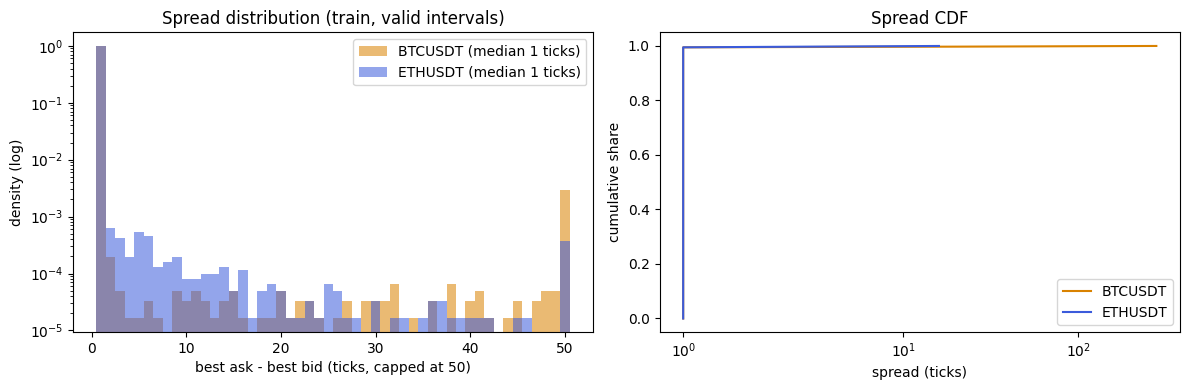

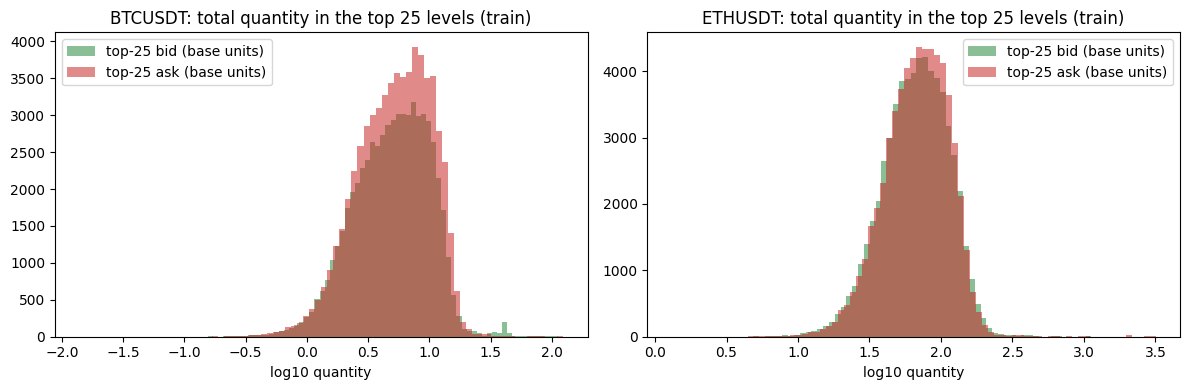

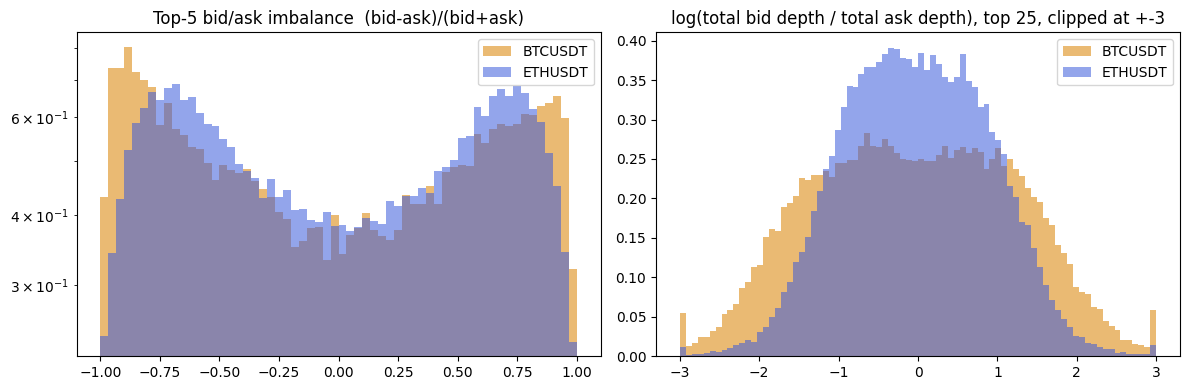

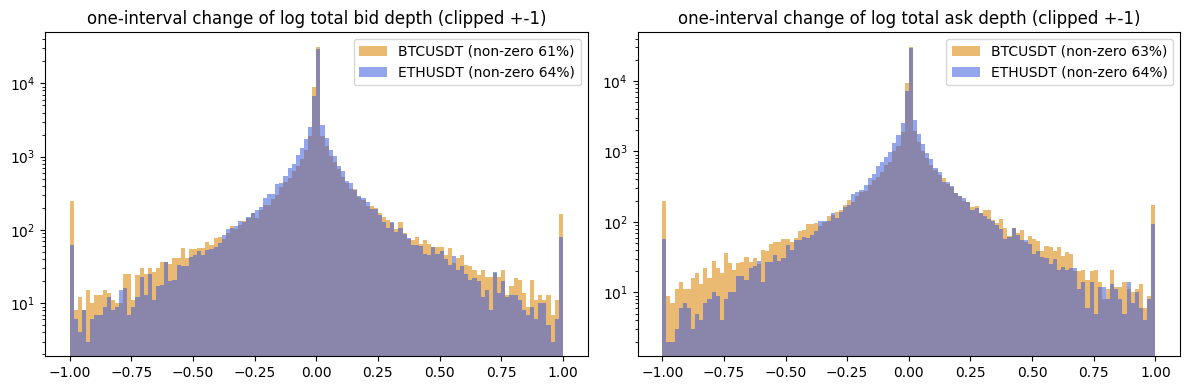

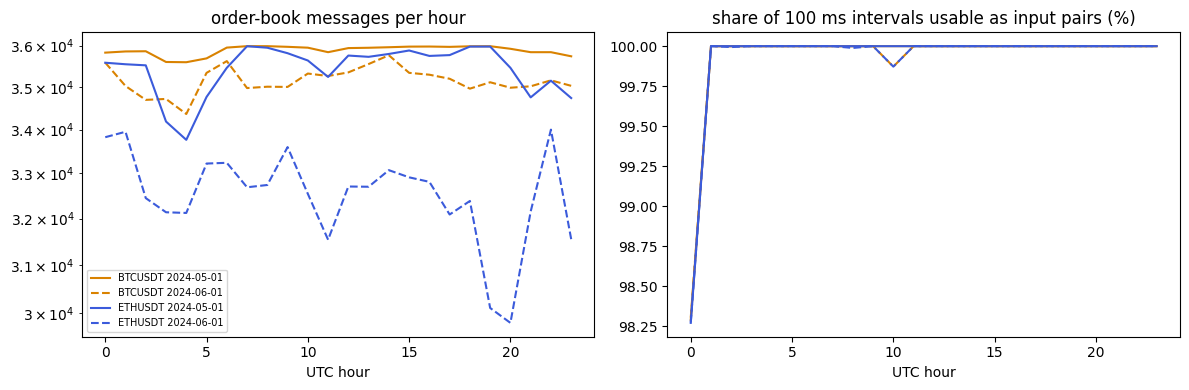

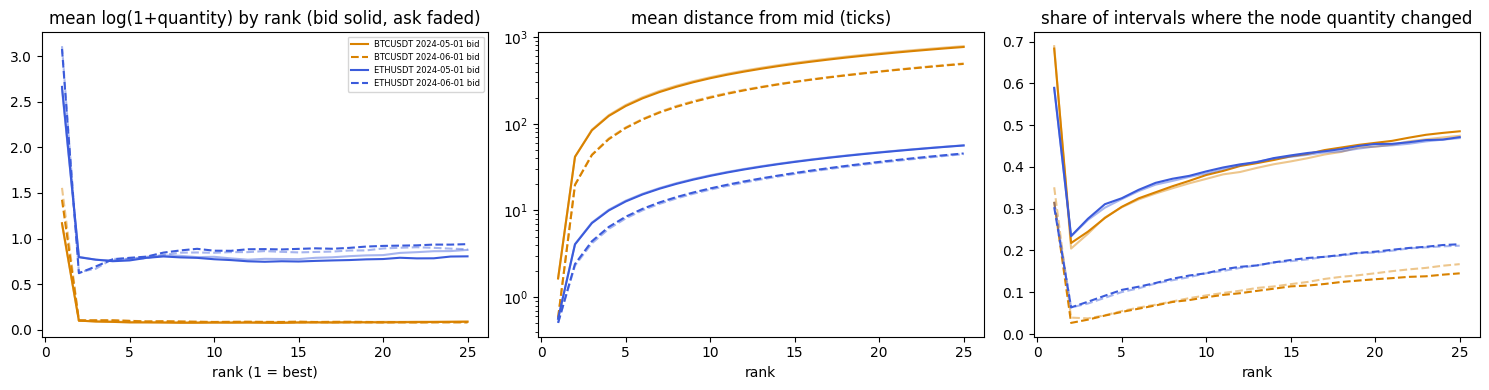

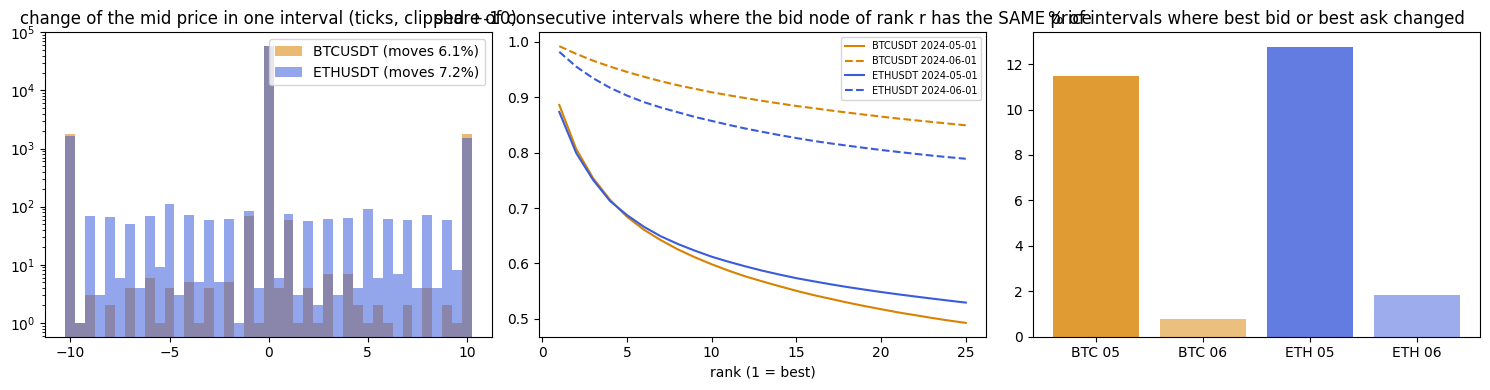

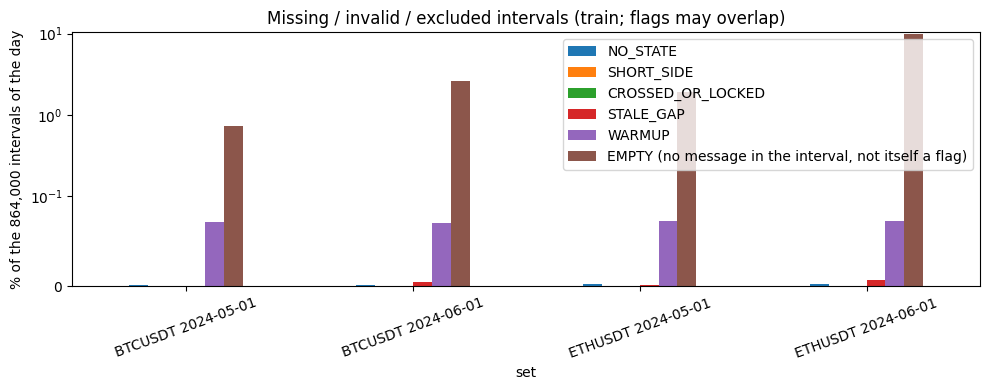

quantiles of per-interval spread (ticks):


,0.0,0.01,0.05,0.25,0.5,0.75,0.95,0.99,0.999,0.9999,1.0
BTCUSDT 2024-05-01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,635.616,2999.297,12120.0
BTCUSDT 2024-06-01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,296.660,5266.0
ETHUSDT 2024-05-01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,32.000,186.000,1000.0
ETHUSDT 2024-06-01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,24.000,113.0


quantiles of |mid change| per 100 ms (ticks):


,0.0,0.01,0.05,0.25,0.5,0.75,0.95,0.99,0.999,0.9999,1.0
BTCUSDT 2024-05-01,0.0,0.0,0.0,0.0,0.0,0.0,333.0,911.0,2170.808,4012.510,12620.5
BTCUSDT 2024-06-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,516.000,1260.658,6006.0
ETHUSDT 2024-05-01,0.0,0.0,0.0,0.0,0.0,0.0,20.0,44.0,100.000,206.662,997.5
ETHUSDT 2024-06-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,46.000,100.000,301.0


extremes and missing (kept in the data; nothing is winsorised or removed):


,tick,median mid price,max level qty (base),max spread (ticks),p99.99 spread (ticks),max |mid change| (ticks),min/max bid levels,longest silent run (intervals),empty intervals %
set,,,,,,,,,
BTCUSDT 2024-05-01,0.01,57865.055,193.841370,12120.0,2999.2968,12620.5,"[0, 29378]",14,0.72
BTCUSDT 2024-06-01,0.01,67705.725,86.954910,5266.0,296.6599,6006.0,"[0, 12988]",54,2.63
ETHUSDT 2024-05-01,0.01,2938.595,3186.538086,1000.0,186.0000,997.5,"[0, 14602]",21,1.89
ETHUSDT 2024-06-01,0.01,3795.005,864.201416,113.0,24.0000,301.0,"[0, 16840]",54,9.88


BTC vs ETH (training days, mean of the two days):


symbol,BTCUSDT,ETHUSDT
median spread (ticks),1.000,1.000
spread == 1 tick (%),99.512,99.561
median mid price,62785.390,3366.800
median top-25 depth bid (base),5.361,69.484
median top-25 depth ask (base),5.746,70.729
mid moves in an interval (%),6.134,7.290
messages per day (M),0.852,0.815
empty intervals (%),1.674,5.884
best bid/ask changes per interval (%),6.135,7.290
rank-misaligned node slots (%),24.922,26.406


PosixPath('/content/drive/MyDrive/research datasets/TGNN_StageC_GraphFeatures_v2/eda/btc_vs_eth_train.csv')

In [ ]:
# ---- EDA: TRAINING DATA ONLY (2024-05-01, 2024-06-01 x BTCUSDT, ETHUSDT) ----
import matplotlib.pyplot as plt
def save_once(path, writer):
    p = Path(path); k = 1
    while p.exists(): p = p.with_name(f'{Path(path).stem}.r{k}{Path(path).suffix}'); k += 1
    writer(p); return p
COL = {'BTCUSDT': '#d98200', 'ETHUSDT': '#3b5bdb'}; LS = {'2024-05-01': '-', '2024-06-01': '--'}
def fig_save(fig, name): fig.tight_layout(); save_once(OUT / 'eda' / name, lambda p: fig.savefig(p, dpi=110)); plt.show(); plt.close(fig)
KEYS = sorted(P1)
def pooled(key, plot_key):
    return {s: np.concatenate([P1[(s, d)]['eda']['plot'][plot_key] for d in SPLITS['train'] if (s, d) in P1]) for s in SYMS}

# 1 spread
sp = pooled('plot', 'spread_ticks'); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in SYMS:
    v = np.minimum(sp[s], 50); ax[0].hist(v, bins=np.arange(0.5, 51.5, 1), alpha=.55, color=COL[s], label=f'{s} (median {np.median(sp[s]):.0f} ticks)', density=True)
    ax[1].plot(np.sort(sp[s])[::max(1, len(sp[s]) // 400)], np.linspace(0, 1, len(np.sort(sp[s])[::max(1, len(sp[s]) // 400)])), color=COL[s], label=s)
ax[0].set_yscale('log'); ax[0].set_xlabel('best ask - best bid (ticks, capped at 50)'); ax[0].set_ylabel('density (log)'); ax[0].set_title('Spread distribution (train, valid intervals)'); ax[0].legend()
ax[1].set_xscale('symlog'); ax[1].set_xlabel('spread (ticks)'); ax[1].set_ylabel('cumulative share'); ax[1].set_title('Spread CDF'); ax[1].legend(); fig_save(fig, 'eda01_spread.png')
# 2 depth
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, s in enumerate(SYMS):
    for side, c in (('depth_bid', '#2b8a3e'), ('depth_ask', '#c92a2a')):
        v = pooled('plot', side)[s]; ax[j].hist(np.log10(v + 1e-9), bins=80, alpha=.55, color=c, label=side.replace('depth_', 'top-25 ') + ' (base units)')
    ax[j].set_title(f'{s}: total quantity in the top 25 levels (train)'); ax[j].set_xlabel('log10 quantity'); ax[j].legend()
fig_save(fig, 'eda02_depth.png')
# 3 imbalance
im = pooled('plot', 'imbalance_top5'); lr = pooled('plot', 'depth_ratio_log'); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in SYMS: ax[0].hist(im[s], bins=60, range=(-1, 1), alpha=.55, color=COL[s], label=s, density=True); ax[1].hist(np.clip(lr[s], -3, 3), bins=80, alpha=.55, color=COL[s], label=s, density=True)
ax[0].set_title('Top-5 bid/ask imbalance  (bid-ask)/(bid+ask)'); ax[0].set_yscale('log'); ax[0].legend(); ax[1].set_title('log(total bid depth / total ask depth), top 25, clipped at +-3'); ax[1].legend(); fig_save(fig, 'eda03_imbalance.png')
# 4 liquidity changes
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, side in enumerate(('dlog_depth_bid', 'dlog_depth_ask')):
    d_ = pooled('plot', side)
    for s in SYMS: ax[j].hist(np.clip(d_[s], -1, 1), bins=120, alpha=.55, color=COL[s], label=f'{s} (non-zero {100 * np.mean(d_[s] != 0):.0f}%)')
    ax[j].set_yscale('log'); ax[j].set_title(f'one-interval change of log total {side[-3:]} depth (clipped +-1)'); ax[j].legend()
fig_save(fig, 'eda04_liquidity_change.png')
# 5 temporal activity
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (s, d) in KEYS:
    e = P1[(s, d)]['eda']; ax[0].plot(range(24), e['messages_per_hour'], color=COL[s], ls=LS[d], label=f'{s} {d}'); ax[1].plot(range(24), 100 * e['valid_share_per_hour'], color=COL[s], ls=LS[d], label=f'{s} {d}')
ax[0].set_yscale('log'); ax[0].set_xlabel('UTC hour'); ax[0].set_title('order-book messages per hour'); ax[0].legend(fontsize=7); ax[1].set_xlabel('UTC hour'); ax[1].set_title('share of 100 ms intervals usable as input pairs (%)'); fig_save(fig, 'eda05_temporal_activity.png')
# 6 depth profile by rank
fig, ax = plt.subplots(1, 3, figsize=(15, 4)); r_ = np.arange(1, 26)
for s in SYMS:
    for d in SPLITS['train']:
        rk = P1[(s, d)]['eda']['rank']; ax[0].plot(r_, rk['logq_mean_bid'], color=COL[s], ls=LS[d], label=f'{s} {d} bid'); ax[0].plot(r_, rk['logq_mean_ask'], color=COL[s], ls=LS[d], alpha=.45)
        ax[1].plot(r_, -rk['dist_ticks_mean_bid'], color=COL[s], ls=LS[d]); ax[1].plot(r_, rk['dist_ticks_mean_ask'], color=COL[s], ls=LS[d], alpha=.45); ax[2].plot(r_, rk['dlogq_nonzero_share_bid'], color=COL[s], ls=LS[d]); ax[2].plot(r_, rk['dlogq_nonzero_share_ask'], color=COL[s], ls=LS[d], alpha=.45)
ax[0].set_title('mean log(1+quantity) by rank (bid solid, ask faded)'); ax[0].set_xlabel('rank (1 = best)'); ax[0].legend(fontsize=6); ax[1].set_title('mean distance from mid (ticks)'); ax[1].set_xlabel('rank'); ax[1].set_yscale('log'); ax[2].set_title('share of intervals where the node quantity changed'); ax[2].set_xlabel('rank'); fig_save(fig, 'eda06_depth_profile_by_rank.png')
# 7 best-price movement and node-rank stability
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for s in SYMS:
    mv = np.concatenate([P1[(s, d)]['eda']['plot']['dmid_ticks'] for d in SPLITS['train']]); ax[0].hist(np.clip(mv, -10, 10), bins=np.arange(-10.25, 10.5, .5), alpha=.55, color=COL[s], label=f'{s} (moves {100 * np.mean(mv != 0):.1f}%)')
    for d in SPLITS['train']:
        rs = P1[(s, d)]['rank']; ax[1].plot(r_, rs['same_price_share_bid_by_rank'], color=COL[s], ls=LS[d], label=f'{s} {d}'); ax[2].bar(f'{s[:3]} {d[5:7]}', rs['either_best_change_share'] * 100, color=COL[s], alpha=.8 if d == SPLITS['train'][0] else .5)
ax[0].set_yscale('log'); ax[0].set_title('change of the mid price in one interval (ticks, clipped +-10)'); ax[0].legend(); ax[1].set_title('share of consecutive intervals where the bid node of rank r has the SAME price'); ax[1].set_xlabel('rank (1 = best)'); ax[1].legend(fontsize=7); ax[2].set_title('% of intervals where best bid or best ask changed'); fig_save(fig, 'eda07_best_price_and_rank_stability.png')
# 8 missing values / flags
FL = pd.DataFrame([{'set': f'{s} {d}', **{k_: v / P1[(s, d)]['eda']['n'] * 100 for k_, v in P1[(s, d)]['eda']['flag_counts'].items()}, 'EMPTY (no message in the interval, not itself a flag)': 100 * P1[(s, d)]['eda']['empty_interval_share']} for s, d in KEYS]).set_index('set')
fig, ax = plt.subplots(figsize=(10, 4)); FL.plot.bar(ax=ax, rot=20); ax.set_ylabel('% of the 864,000 intervals of the day'); ax.set_yscale('symlog', linthresh=.1); ax.set_title('Missing / invalid / excluded intervals (train; flags may overlap)'); fig_save(fig, 'eda08_flags.png')
# tables
def qtab(name):
    return pd.DataFrame({f'{s} {d}': P1[(s, d)]['eda']['quant'][name] for (s, d) in KEYS}).T
for name in ('spread_ticks', 'imbalance_top5', 'depth25_bid_base', 'depth25_ask_base', 'mid_change_ticks', 'dlog_depth_bid'):
    t_ = qtab(name); save_once(OUT / 'eda' / f'quantiles_{name}.csv', lambda p, t_=t_: t_.to_csv(p));
print('quantiles of per-interval spread (ticks):'); display(qtab('spread_ticks').round(3))
print('quantiles of |mid change| per 100 ms (ticks):'); display(qtab('abs_mid_change_ticks').round(3))
EXT = pd.DataFrame([{'set': f'{s} {d}', 'tick': P1[(s, d)]['tick'], 'median mid price': P1[(s, d)]['eda']['mid_price_median'], 'max level qty (base)': P1[(s, d)]['eda']['max_level_qty'], 'max spread (ticks)': P1[(s, d)]['eda']['quant']['spread_ticks']['1.0'], 'p99.99 spread (ticks)': P1[(s, d)]['eda']['quant']['spread_ticks']['0.9999'], 'max |mid change| (ticks)': P1[(s, d)]['eda']['quant']['abs_mid_change_ticks']['1.0'], 'min/max bid levels': P1[(s, d)]['eda']['nbid_min_max'], 'longest silent run (intervals)': P1[(s, d)]['eda']['longest_silent_run_intervals'], 'empty intervals %': round(100 * P1[(s, d)]['eda']['empty_interval_share'], 2)} for s, d in KEYS]).set_index('set')
print('extremes and missing (kept in the data; nothing is winsorised or removed):'); display(EXT); save_once(OUT / 'eda' / 'extremes_and_missing.csv', lambda p: EXT.to_csv(p))
# BTC vs ETH summary
CMP = []
for s in SYMS:
    es = [P1[(s, d)]['eda'] for d in SPLITS['train']]; rs = [P1[(s, d)]['rank'] for d in SPLITS['train']]
    CMP.append({'symbol': s, 'median spread (ticks)': np.mean([e['quant']['spread_ticks']['0.5'] for e in es]), 'spread == 1 tick (%)': 100 * np.mean([e['spread_ticks_share_eq1'] for e in es]), 'median mid price': np.mean([e['mid_price_median'] for e in es]),
                'median top-25 depth bid (base)': np.mean([e['quant']['depth25_bid_base']['0.5'] for e in es]), 'median top-25 depth ask (base)': np.mean([e['quant']['depth25_ask_base']['0.5'] for e in es]), 'mid moves in an interval (%)': 100 * np.mean([e['mid_change_nonzero_share'] for e in es]),
                'messages per day (M)': np.mean([P1[(s, d)]['replay']['messages'] for d in SPLITS['train']]) / 1e6, 'empty intervals (%)': 100 * np.mean([e['empty_interval_share'] for e in es]), 'best bid/ask changes per interval (%)': 100 * np.mean([r['either_best_change_share'] for r in rs]), 'rank-misaligned node slots (%)': 100 * np.mean([r['rank_misaligned_share_all_nodes'] for r in rs]),
                'top-25 price-set overlap (median)': np.mean([r['top25_price_set_overlap_median'] for r in rs])})
CMP = pd.DataFrame(CMP).set_index('symbol').T; print('BTC vs ETH (training days, mean of the two days):'); display(CMP.round(3)); save_once(OUT / 'eda' / 'btc_vs_eth_train.csv', lambda p: CMP.to_csv(p))

## 7 · Fit the scaler on the training days only, then freeze it

In [ ]:
# ---- fit the scaler on TRAINING days only, then FREEZE it ----
mom_n = S.merge_moments([P1[k_]['mom_node'] for k_ in sorted(P1)]); mom_g = S.merge_moments([P1[k_]['mom_glob'] for k_ in sorted(P1)]); SC = S.scaler_from_moments(mom_n, mom_g)
SC['fitted_on'] = [f'{s} {d}' for s, d in sorted(P1)]; SC['unscaled_node_channels'] = [S.NODE_FEATS[i] for i in range(len(S.NODE_FEATS)) if i not in S.SCALED_NODE]; SC['scaling_rule'] = '(x - mean) / std with ONE mean/std per channel shared by all 50 nodes (and both symbols); intervals flagged NO_STATE/SHORT_SIDE are zero-filled'
SC_SHA = S.canonical_sha({k_: v for k_, v in SC.items()})
sc_path = OUT / 'config' / 'scaler_train_only.json'
if sc_path.exists():
    old = json.loads(sc_path.read_text()); assert S.canonical_sha(old['scaler']) == SC_SHA, 'Re-fitting the scaler gave a different result than the saved one - do not continue (stop and show this message).'
    print('scaler already saved and re-derived identically:', SC_SHA[:16])
else:
    S.dump_json({'scaler': SC, 'sha256': SC_SHA, 'saved_utc': pd.Timestamp.now(tz='UTC').isoformat()}, sc_path); print('scaler saved (frozen):', SC_SHA[:16])
display(pd.DataFrame({'channel': SC['node_channels'], 'mean': SC['node_mean'], 'std': SC['node_std'], 'std floored': SC['node_std_floored']}))
display(pd.DataFrame({'channel': SC['glob_channels'], 'mean': SC['glob_mean'], 'std': SC['glob_std'], 'std floored': SC['glob_std_floored']}))
print('values used:', SC['n_node_values'], 'node values,', SC['n_glob_values'], 'global values. Validation/test days are NOT in this fit.')

scaler saved (frozen): 2bfe9d4985698ba2


,channel,mean,std,std floored
0,dist_ticks,1.542126e+00,308.616593,0
1,log_qty,5.193332e-01,0.740950,0
2,d_log_qty,-9.850156e-08,0.374426,0
3,cum_log_depth,2.628404e+00,1.264880,0
4,dist_slog,4.317225e-03,4.475120,0


,channel,mean,std,std floored
0,log_spread_ticks,0.705949,0.221887,0
1,imbalance_top5,-0.014804,0.606932,0
2,mid_change_signed_log,-0.000468,1.113998,0


values used: 172671700 node values, 3453434 global values. Validation/test days are NOT in this fit.


## 8 · Phase 2 — build the scaled float16 graph tensors of all 12 days with the frozen scaler

In [ ]:
# ---- Phase 2: build the tensors of ALL 12 days with the frozen scaler (resumable; a day is accepted only when its set_summary.json exists) ----
t_p2 = time.time(); todo = []; P2 = {}
for sym, day, split in SETS:
    fin = OUT / 'sets' / f'{sym}_{day}'
    if (fin / 'set_summary.json').exists():
        sm = json.loads((fin / 'set_summary.json').read_text()); assert sm.get('scaler_sha256') == SC_SHA, f'{sym} {day} was built with a different scaler'; P2[(sym, day)] = {'sym': sym, 'day': day, 'skipped_existing': True, 'summary': sm}; print('   already built:', sym, day)
    else: todo.append({'base': str(BASE), 'sym': sym, 'day': day, 'split': split, 'scratch': str(SCRATCH), 'out_sets': str(OUT / 'sets'), 'scaler': SC, 'scaler_sha': SC_SHA, 'verbose': N_WORKERS <= 1})
print(f'phase 2: {len(todo)} day(s) to build with {N_WORKERS} worker(s)')
for key, r in run_pool(S.process_phase2, todo, N_WORKERS).items():
    assert 'error' not in r, f'{key} failed:\n' + r['error']
    P2[key] = r
P2_SECONDS = round(time.time() - t_p2, 1); SUM = {k_: v['summary'] for k_, v in P2.items()}
rows = []
for sym, day, split in SETS:
    sm = SUM[(sym, day)]; rows.append({'split': split, 'sym': sym, 'day': day, 'windows': sm['n_windows'], 'flag-free %': round(100 * sm['flag_free_intervals'] / sm['n_intervals'], 2), 'windows % of day': round(100 * sm['n_windows'] / sm['n_intervals'], 2), 'snapshot match top25 %': None if sm['snapshot_check'].get('share_equal_top25') is None else round(100 * sm['snapshot_check']['share_equal_top25'], 2), 'comparable': sm['snapshot_check'].get('comparable'), 'seconds': sm['seconds'], 'peak RAM GB': sm['peak_rss_gb']})
SETTAB = pd.DataFrame(rows); display(SETTAB); print('phase 2 wall time:', P2_SECONDS, 's')

phase 2: 12 day(s) to build with 2 worker(s)
   done ETHUSDT 2024-05-01 ok
   done BTCUSDT 2024-05-01 ok
   done BTCUSDT 2024-06-01 ok
   done ETHUSDT 2024-06-01 ok
   done ETHUSDT 2024-07-01 ok
   done BTCUSDT 2024-07-01 ok
   done ETHUSDT 2024-08-01 ok
   done BTCUSDT 2024-08-01 ok
   done BTCUSDT 2024-09-01 ok
   done ETHUSDT 2024-09-01 ok
   done ETHUSDT 2024-10-01 ok
   done BTCUSDT 2024-10-01 ok


,split,sym,day,windows,flag-free %,windows % of day,snapshot match top25 %,comparable,seconds,peak RAM GB
0,train,BTCUSDT,2024-05-01,863335,99.93,99.92,100.0,786966,390.3,1.82
1,train,ETHUSDT,2024-05-01,863328,99.93,99.92,100.0,767817,374.5,1.91
2,train,BTCUSDT,2024-06-01,863244,99.92,99.91,100.0,556828,281.1,2.27
3,train,ETHUSDT,2024-06-01,863127,99.92,99.90,100.0,600718,304.2,1.85
4,val,BTCUSDT,2024-07-01,863280,99.93,99.92,100.0,672233,454.2,2.27
5,val,ETHUSDT,2024-07-01,862709,99.93,99.85,100.0,629993,367.3,2.21
6,test,BTCUSDT,2024-08-01,863337,99.93,99.92,100.0,790793,800.1,2.99
7,test,ETHUSDT,2024-08-01,863339,99.93,99.92,100.0,791908,545.2,2.97
8,test,BTCUSDT,2024-09-01,863266,99.93,99.92,100.0,733280,581.4,2.97
9,test,ETHUSDT,2024-09-01,863267,99.93,99.92,100.0,709810,442.4,2.99


phase 2 wall time: 2953.3 s


## 9 · D-tests on the produced data

In [ ]:
# ---- D-tests on the produced data ----
def T(i, fam, name, ok, det): TESTS.append((i, fam, name, bool(ok), det))
NDAY = S.N_INT; SET_KEYS = [(s, d) for s, d, _ in SETS]; SPLIT_OF = {(s, d): sp for s, d, sp in SETS}
def load(sym, day):
    f = OUT / 'sets' / f'{sym}_{day}'; return {n: np.load(f / f'{n}.npy', mmap_mode='r') for n in ('nodes', 'glob', 'flags', 'n_msgs', 'win_end')}
ARR = {k_: load(*k_) for k_ in SET_KEYS}
RSTAT = {k_: (P1[k_]['replay'] if k_ in P1 else SUM[k_]['replay']) for k_ in SET_KEYS}
# D01 shapes and side channel
bad = []
for k_, a in ARR.items():
    if a['nodes'].shape != (NDAY, 2 * S.K, len(S.NODE_FEATS)) or a['nodes'].dtype != np.float16: bad.append((k_, 'nodes', a['nodes'].shape, str(a['nodes'].dtype)))
    if a['glob'].shape != (NDAY, len(S.GLOB_FEATS)) or a['flags'].shape != (NDAY,) or a['n_msgs'].shape != (NDAY,) or a['win_end'].ndim != 1: bad.append((k_, 'other shapes'))
    rows_ = np.sort(np.random.default_rng(7).choice(NDAY, 2000, replace=False)); sd = np.asarray(a['nodes'][rows_][:, :, 0], dtype=np.float32)
    if not (np.all(sd[:, :S.K] == -1) and np.all(sd[:, S.K:] == 1)): bad.append((k_, 'side channel'))
T('D01', 'D', 'graph tensor shapes: nodes (864000, 50, 5) float16 [25 bid ranks then 25 ask ranks], global (864000, 3), flags/n_msgs (864000,), side channel -1 (bid) / +1 (ask)', not bad, f'{len(SET_KEYS)} days checked, problems: {bad[:3]}')
# D02 feature correctness (independent recomputation + provider snapshots)
mx = max(SUM[k_]['checks']['scalar_vs_stored_max_rel_diff'] for k_ in SET_KEYS); nchk = sum(SUM[k_]['checks']['n_scalar_checked'] for k_ in SET_KEYS)
T('D02a', 'D', 'stored (scaled, float16) features equal an independent pure-python recomputation at random windows (last input interval and target interval)', mx < 2e-3 and nchk > 0, f'{nchk} intervals checked, max relative difference {mx:.2e} (float16 rounding is about 5e-4)')
snaps = {k_: SUM[k_]['snapshot_check'] for k_ in SET_KEYS}; low = [(k_, round(v.get('share_equal_top25') or 0, 4), v.get('comparable')) for k_, v in snaps.items() if (v.get('comparable') or 0) < 100 or (v.get('share_equal_top25') or 0) < SNAP_MIN_SHARE]
T('D02b', 'D', f'reconstructed top-25 equals the provider book_snapshot_25 (price and quantity) on at least {int(100 * SNAP_MIN_SHARE)}% of comparable intervals, per day (same feed: consistency, NOT independent validation)', not low, f'days below the threshold or with <100 comparable intervals: {low}')
# D03 timestamp ordering
inv = {k_: v['local_inversions'] for k_, v in RSTAT.items()}; oo = {k_: (v['rows_before_day'], v['rows_after_day']) for k_, v in RSTAT.items()}
T('D03', 'D', 'timestamps: local_timestamp is non-decreasing in every file (the replay stops with an error otherwise); the 864,000-interval grid is strictly increasing by construction', all(v == 0 for v in inv.values()), f'inversions per day: {sorted(set(inv.values()))}; rows outside the UTC day (before, after) per day: {dict((f"{k_[0][:3]} {k_[1]}", v) for k_, v in oo.items() if v != (0, 0))}')
# D04 missing / invalid values
nf = sum(SUM[k_]['tensor_stats']['nonfinite_before_cast'] for k_ in SET_KEYS); clip = sum(SUM[k_]['tensor_stats']['f16_clipped_values'] for k_ in SET_KEYS); dr = {f'{k_[0][:3]} {k_[1]}': RSTAT[k_]['dropped_invalid_rows'] for k_ in SET_KEYS}; nowin = [k_ for k_ in SET_KEYS if SUM[k_]['n_windows'] == 0]
T('D04', 'D', 'missing/invalid values: tensors contain no NaN/inf, no value needed float16 clipping, invalid raw rows are dropped and counted, every day still has windows', nf == 0 and clip == 0 and not nowin, f'non-finite={nf}, clipped={clip}, dropped invalid raw rows per day={dr}, days without windows={nowin}')
# D05 causal feature generation on REAL data: replaying only the first rows reproduces the first states exactly
key = ('BTCUSDT', '2024-06-01'); bk, sn = S.raw_paths(BASE, *key); d0 = S.day0_of(key[1]); tick = S.tick_infer(bk)
Lfull = S.load_levels(SCRATCH / f'{key[0]}_{key[1]}') if (SCRATCH / f'{key[0]}_{key[1]}' / 'nask.npy').exists() else S.replay_day(bk, d0, tick, verbose=False)[0]
NR = min(3_000_000, RSTAT[key]['rows'] // 2); Ltr, st_tr = S.replay_day(bk, d0, tick, max_rows=NR, verbose=False); kmax = int(np.flatnonzero(Ltr['n_rows'] > 0).max()); kk = kmax - 1
same = all(np.array_equal(Ltr[n][:kk], Lfull[n][:kk]) for n in ('bid_px', 'bid_q', 'ask_px', 'ask_q', 'nbid', 'nask')); fl_f = S.make_flags(Lfull); fl_t = S.make_flags({n: Ltr[n] for n in Ltr}); feat_same = True
for a0 in range(0, kk, 50_000):                      # chunked so that a long prefix does not need gigabytes
    fa, ga = S.raw_features(Lfull, a0, min(a0 + 50_000, kk)); fb, gb = S.raw_features(Ltr, a0, min(a0 + 50_000, kk)); feat_same &= bool(np.array_equal(fa, fb) and np.array_equal(ga, gb))
T('D05', 'D', f'causal generation on real data: states and raw features of intervals 0..{kk - 1} are identical whether the replay sees only the first {NR:,} rows or the whole day; flags use only the past', same and feat_same and np.array_equal(fl_f[:kk - 1], fl_t[:kk - 1]), f'states identical={same}, features identical={feat_same}, flags identical={np.array_equal(fl_f[:kk - 1], fl_t[:kk - 1])}')
del Lfull, Ltr; gc.collect()
# D06 input / target separation
prob = []; rng = np.random.default_rng(99)
for k_, a in ARR.items():
    w = np.asarray(a['win_end']); fl = np.asarray(a['flags'])
    if len(w) == 0: continue
    for t in rng.choice(w, size=min(3000, len(w)), replace=False):
        (lo, hi), tg = S.window_slices(int(t))
        if not (lo >= 1 and tg < NDAY and tg >= hi and not (fl[lo - 1:tg + 1] != 0).any() and tg not in range(lo, hi)): prob.append((k_, int(t)))
    # every flag-free run of length >= 52 has to produce windows: count equality, computed a second way
    g = (fl == 0).astype(np.int8); n_alt = int((np.lib.stride_tricks.sliding_window_view(g, S.SEQ + 2).sum(1) == S.SEQ + 2).sum())
    if n_alt != len(w): prob.append((k_, 'window count', n_alt, len(w)))
TARGET_NOTE = 'target of the window ending at t = scaled log_qty of the 50 nodes and scaled log_spread_ticks at interval t+1; inputs end at interval t'
T('D06', 'D', 'input/target separation: inputs are intervals t-49..t, the target is interval t+1 only, no shared interval; a window exists exactly when intervals t-50..t+1 are all flag-free (count verified by a second method on every day)', not prob, f'problems: {prob[:3]}. {TARGET_NOTE}')
# D07 scaler fitted on training days only and applied frozen
sha_ok = all(SUM[k_].get('scaler_sha256') == SC_SHA for k_ in SET_KEYS); fit_days = sorted(SC['fitted_on']); train_days = sorted(f'{s} {d}' for s, d in SET_KEYS if SPLIT_OF[(s, d)] == 'train')
t_sc = sc_path.stat().st_mtime; later = all((OUT / 'sets' / f'{s}_{d}' / 'set_summary.json').stat().st_mtime >= t_sc for s, d in SET_KEYS if SPLIT_OF[(s, d)] != 'train')
sm_ = np.zeros(3); sq_ = np.zeros(3); cnt = 0                               # standardisation check on the stored TRAIN tensors (channels 1..3 of the nodes)
for k_ in SET_KEYS:
    if SPLIT_OF[k_] != 'train': continue
    a = ARR[k_]; fl = np.asarray(a['flags']); ok = (fl == 0); ok[1:] &= (fl[:-1] == 0); ok[0] = False
    for s0 in range(0, NDAY, 100_000):
        m = ok[s0:s0 + 100_000]
        if not m.any(): continue
        x = np.asarray(a['nodes'][s0:s0 + 100_000][m][:, :, 1:4], dtype=np.float64).reshape(-1, 3); sm_ += x.sum(0); sq_ += (x ** 2).sum(0); cnt += len(x)
mean_ = sm_ / cnt; std_ = np.sqrt(sq_ / cnt - mean_ ** 2)
T('D07', 'D', 'scaler: fitted on the 4 training days only, saved before any validation/test day was built, identical hash in every day, and the stored TRAIN tensors have mean ~0 / std ~1 on dist, log_qty, d_log_qty', sha_ok and fit_days == train_days and later and np.all(np.abs(mean_) < 0.01) and np.all(np.abs(std_ - 1) < 0.03), f'fitted on {fit_days}; hash identical={sha_ok}; scaler file older than val/test builds={later}; train mean={np.round(mean_, 4).tolist()} std={np.round(std_, 4).tolist()} (std floored flags: {SC["node_std_floored"]})')
# D08 no cross-day windows
bad = []
for k_, a in ARR.items():
    w = np.asarray(a['win_end'])
    if len(w) and (int(w.min()) < S.SEQ or int(w.max()) > NDAY - 2): bad.append(k_)
T('D08', 'D', 'no cross-day windows: every day is its own 864,000-interval file; all window ends lie in [50, 863,998] so inputs and target stay inside the same UTC day; the first 600 intervals after the first snapshot are excluded as warm-up', not bad and all(SUM[k_]['n_intervals'] == NDAY for k_ in SET_KEYS), f'violations: {bad}; earliest window end per day (min over days) = {min(SUM[k_]["win_min"] for k_ in SET_KEYS if SUM[k_]["win_min"] is not None)}')
# D09 deterministic regeneration
if RUN_REGEN_TEST:
    t0 = time.time(); key = ('BTCUSDT', '2024-06-01'); bk, sn = S.raw_paths(BASE, *key); d0 = S.day0_of(key[1]); tick = S.tick_infer(bk); tmpd = WORKDIR / 'stagec_regen'; shutil.rmtree(tmpd, ignore_errors=True)
    Lr, _ = S.replay_day(bk, d0, tick, verbose=False); flr = S.make_flags(Lr); S.build_tensors(Lr, flr, SC, tmpd); del Lr
    hs = {n: S.sha256_file(tmpd / n) for n in ('nodes.npy', 'glob.npy', 'flags.npy', 'n_msgs.npy', 'win_end.npy')}; ref = SUM[key]['hashes']; same = {n: hs[n] == ref[n] for n in hs}; shutil.rmtree(tmpd, ignore_errors=True)
    T('D09', 'D', 'deterministic regeneration: rebuilding BTCUSDT 2024-06-01 from the raw file gives byte-identical tensor files (SHA-256)', all(same.values()), f'{same} ({time.time() - t0:.0f} s)')
else:
    T('D09', 'D', 'deterministic regeneration (SKIPPED by the setting RUN_REGEN_TEST=False)', False, 'not run')
# D10 rank-change frequency (training days; used for the readiness rule)
rk_tr = [P1[k_]['rank'] for k_ in sorted(P1)]; mis = float(np.mean([r['rank_misaligned_share_all_nodes'] for r in rk_tr])); eb = float(np.mean([r['either_best_change_share'] for r in rk_tr])); ov = float(np.mean([r['top25_price_set_overlap_median'] for r in rk_tr]))
T('D10', 'D', 'node-rank stability measured on training days (rank-change frequency); finite and recorded for the readiness rule', all(np.isfinite([mis, eb, ov])), f'node slots whose price level changes between consecutive valid intervals: {100 * mis:.1f}% (risk threshold {100 * RANK_RISK_SHARE:.0f}%); best bid or ask moves in {100 * eb:.1f}% of intervals; median top-25 price-set overlap {ov:.3f}')
# D11 book-only
sch_names = S.NODE_FEATS + S.GLOB_FEATS; paths_ok = all('trades' not in p.name for k_ in SET_KEYS for p in S.raw_paths(BASE, *k_))
T('D11', 'D', 'book-only: no feature or target name refers to trades, and the loader only ever receives the incremental-book and book-snapshot paths', paths_ok and not any(('trade' in n or 'volume' in n or 'aggress' in n) for n in sch_names), f'features: {sch_names}')
# D12 raw inputs untouched and frozen artefacts untouched
FP_AUD_AFTER = {}
for d in AUDITED: FP_AUD_AFTER.update(fp_tree(d))
FP_TOP_AFTER = fp_top({OUT.name}); chg_a = [k_ for k_ in FP_AUD_BEFORE if FP_AUD_AFTER.get(k_) != FP_AUD_BEFORE[k_]]; new_a = [k_ for k_ in FP_AUD_AFTER if k_ not in FP_AUD_BEFORE]; chg_t = [k_ for k_ in set(FP_TOP_BEFORE) | set(FP_TOP_AFTER) if FP_TOP_BEFORE.get(k_) != FP_TOP_AFTER.get(k_)]
T('D12', 'D', 'nothing outside the new output folder changed: the 12 audited folders (every file) and all other entries of the research-datasets folder (frozen Autoencoder / XGBoost / Transformer artefacts included) have the same names, sizes and modification times as before', not chg_a and not new_a and not chg_t, f'changed audited files: {chg_a[:3]}, new audited files: {new_a[:3]}, changed/new top-level entries: {chg_t[:3]}')
TD = pd.DataFrame(TESTS, columns=['id', 'family', 'name', 'passed', 'detail']); TD['result'] = np.where(TD.passed, 'PASS', 'FAIL'); display(TD[['id', 'result', 'name', 'detail']])
print(f'\nE-tests: {int(TD[TD.family == "E"].passed.sum())}/{(TD.family == "E").sum()} PASS | D-tests: {int(TD[TD.family == "D"].passed.sum())}/{(TD.family == "D").sum()} PASS')

,id,result,name,detail
0,E01,PASS,causal 100 ms replay equals an independent bru...,"1000 interval states compared, 0 mismatches"
1,E02,PASS,changing every message after interval 800 leav...,"identical_before=True, later_states_differ=True"
2,E03,PASS,vectorised feature code equals an independent ...,max abs difference 0.00e+00
3,E04,PASS,rows with NaN / non-positive price or negative...,"dropped=9 (expected 9), book identical to the ..."
4,E05,PASS,a flagged interval removes exactly the windows...,"window_rule=True, flags_prefix_equal=True"
5,E06,PASS,chunked (Chan) moments equal numpy; applying a...,max moment error 1.87e-14
6,E07,PASS,tensor files are bit-identical for different c...,"identical=True, shape=(1500, 50, 6), windows=401"
7,E08,PASS,"window definition: input intervals t-49..t, ta...","input=[151,201) target=201"
8,D01,PASS,"graph tensor shapes: nodes (864000, 50, 5) flo...","12 days checked, problems: []"
9,D02a,PASS,"stored (scaled, float16) features equal an ind...","192 intervals checked, max relative difference..."



E-tests: 8/8 PASS | D-tests: 13/13 PASS


## 10 · Measured resources and the stand-in benchmark (forward + backward only; no learning)

In [ ]:
# ---- measured resources + stand-in benchmark ----
tot_bytes = sum(f.stat().st_size for f in (OUT / 'sets').rglob('*') if f.is_file()); per_day_gb = tot_bytes / len(SET_KEYS) / 1e9
BUILD_S = {f'{k_[0]} {k_[1]}': SUM[k_]['seconds'] for k_ in SET_KEYS}; peak_ram = max(SUM[k_]['peak_rss_gb'] for k_ in SET_KEYS); peak_ram = max(peak_ram, max(P1[k_]['replay']['peak_rss_gb'] for k_ in P1))
NW = {k_: SUM[k_]['n_windows'] for k_ in SET_KEYS}; n_train_w = sum(v for k_, v in NW.items() if SPLIT_OF[k_] == 'train')
RES = {'hardware': HW, 'tensor_storage_gb_total': round(tot_bytes / 1e9, 3), 'tensor_storage_gb_per_day': round(per_day_gb, 3), 'phase1_wall_s': P1_SECONDS, 'phase2_wall_s': P2_SECONDS, 'replay_seconds_per_day': {f'{k_[0]} {k_[1]}': (P1[k_]['replay']['seconds'] if k_ in P1 else SUM[k_]['replay'].get('seconds') if isinstance(SUM[k_]['replay'], dict) else None) for k_ in SET_KEYS},
       'build_seconds_per_day': BUILD_S, 'peak_worker_ram_gb': peak_ram, 'workers': N_WORKERS, 'scratch_gb': round(sum(f.stat().st_size for f in SCRATCH.rglob('*') if f.is_file()) / 1e9, 2) if SCRATCH.exists() else 0, 'windows_train': n_train_w, 'windows_per_split': {sp: sum(v for k_, v in NW.items() if SPLIT_OF[k_] == sp) for sp in ('train', 'val', 'test')}, 'note': 'wall times include whatever was resumed/skipped; per-day numbers are the measured ones'}
print(json.dumps({k_: v for k_, v in RES.items() if k_ not in ('hardware', 'replay_seconds_per_day', 'build_seconds_per_day')}, indent=1))
BENCH = {'ran': False}
if HAVE_TORCH:
    import torch, torch.nn as nn
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); torch.manual_seed(0)
    A = np.eye(51, dtype=np.float32)                                                # STAND-IN topology: chain inside each side, best bid <-> best ask, global node <-> every node
    for s0 in (0, 25):
        for r in range(24): A[s0 + r, s0 + r + 1] = A[s0 + r + 1, s0 + r] = 1
    A[0, 25] = A[25, 0] = 1; A[50, :] = 1; A[:, 50] = 1; A = A / A.sum(1, keepdims=True)
    class StandIn(nn.Module):
        def __init__(s, f=len(S.NODE_FEATS), g=len(S.GLOB_FEATS), h=64):
            super().__init__(); s.enc = nn.Sequential(nn.Linear(f, h), nn.ReLU(), nn.Linear(h, h)); s.genc = nn.Linear(g, h); s.m1 = nn.Linear(h, h); s.m2 = nn.Linear(h, h); s.gru = nn.GRU(h * 3, h, batch_first=True); s.out = nn.Linear(h, 2 * S.K + 1); s.register_buffer('A', torch.tensor(A))
        def forward(s, x, g):                                                          # x (B,T,50,F) g (B,T,G)
            B, T_ = x.shape[:2]; h = torch.cat([s.enc(x), s.genc(g).unsqueeze(2)], 2)  # (B,T,51,h)
            h = torch.relu(torch.einsum('ij,btjh->btih', s.A, s.m1(h))); h = torch.relu(torch.einsum('ij,btjh->btih', s.A, s.m2(h)))
            z = torch.cat([h[:, :, :25].mean(2), h[:, :, 25:50].mean(2), h[:, :, 50]], -1); o, _ = s.gru(z); return s.out(o[:, -1])
    model = StandIn().to(dev); nparams = sum(p.numel() for p in model.parameters()); bs = 64; train_keys = [k_ for k_ in SET_KEYS if SPLIT_OF[k_] == 'train']; rngb = np.random.default_rng(5)
    def get_batch():
        xs, gs, ys = [], [], []
        for _ in range(bs):
            k_ = train_keys[rngb.integers(len(train_keys))]; a = ARR[k_]; t = int(a['win_end'][rngb.integers(len(a['win_end']))]); (lo, hi), tg = S.window_slices(t)
            xs.append(np.asarray(a['nodes'][lo:hi], dtype=np.float32)); gs.append(np.asarray(a['glob'][lo:hi], dtype=np.float32)); ys.append(np.concatenate([np.asarray(a['nodes'][tg][:, 2], dtype=np.float32), np.asarray(a['glob'][tg][0:1], dtype=np.float32)]))
        return torch.tensor(np.stack(xs)), torch.tensor(np.stack(gs)), torch.tensor(np.stack(ys))
    ps = psutil.Process(); rss0 = ps.memory_info().rss; t_load = []; t_fb = []
    if dev.type == 'cuda': torch.cuda.reset_peak_memory_stats()
    for it in range(25):
        t0 = time.time(); x, g, y = get_batch(); t1 = time.time(); x, g, y = x.to(dev), g.to(dev), y.to(dev)
        loss = ((model(x, g) - y) ** 2).mean(); loss.backward(); model.zero_grad(set_to_none=True)
        if dev.type == 'cuda': torch.cuda.synchronize()
        t2 = time.time()
        if it >= 5: t_load.append(t1 - t0); t_fb.append(t2 - t1)
    peak_gpu = torch.cuda.max_memory_allocated() / 1e9 if dev.type == 'cuda' else None; rss_delta = (ps.memory_info().rss - rss0) / 1e9
    ms_fb = 1000 * float(np.median(t_fb)); ms_load = 1000 * float(np.median(t_load)); epoch_min = n_train_w / bs * (ms_fb + ms_load) / 60000
    BENCH = {'ran': True, 'device': str(dev), 'standin_params': nparams, 'batch_size': bs, 'median_ms_forward_backward': round(ms_fb, 1), 'median_ms_batch_load': round(ms_load, 1), 'peak_gpu_gb': peak_gpu, 'rss_delta_gb': round(rss_delta, 2), 'train_windows': n_train_w, 'epoch_minutes_all_windows': round(epoch_min, 1), 'epoch_minutes_10pct_windows': round(epoch_min / 10, 1),
             'caveat': 'stand-in network (graph smoothing + GRU, no optimiser step, weights discarded): it measures data-loading and compute cost only; the real TGNN will differ'}
    del model
else:
    BENCH = {'ran': False, 'reason': 'torch is not installed in this runtime'}
RES['benchmark'] = BENCH; print(json.dumps(BENCH, indent=1))
FREE_NOW = round(shutil.disk_usage(str(BASE)).free / 1e9, 2)
feas = {'storage': FREE_NOW >= tot_bytes / 1e9 * (STORAGE_MARGIN - 1.0), 'ram': peak_ram < MAX_RAM_FRAC * HW['ram_total_gb'], 'epoch_time': bool(BENCH.get('ran')) and BENCH['epoch_minutes_all_windows'] <= MAX_EPOCH_MIN}
RES['feasibility_checks'] = feas
T('R01', 'R', f'storage: tensors written ({tot_bytes / 1e9:.2f} GB) were written and the Drive still has {FREE_NOW} GB free (at least {int(100 * (STORAGE_MARGIN - 1))}% of the tensor size)', feas['storage'], f'{per_day_gb:.2f} GB per day')
T('R02', 'R', f'memory: peak RAM of a worker ({peak_ram:.2f} GB) below {int(100 * MAX_RAM_FRAC)}% of the {HW["ram_total_gb"]} GB machine (workers in parallel: {N_WORKERS})', feas['ram'], f'peak {peak_ram:.2f} GB per worker')
T('R03', 'R', f'runtime: stand-in forward+backward over ALL training windows is at most {MAX_EPOCH_MIN} min per epoch on this machine', feas['epoch_time'], f'{BENCH.get("epoch_minutes_all_windows")} min per epoch on {BENCH.get("device")} for {n_train_w:,} windows (10% subsample: {BENCH.get("epoch_minutes_10pct_windows")} min)')
TD = pd.DataFrame(TESTS, columns=['id', 'family', 'name', 'passed', 'detail']); TD['result'] = np.where(TD.passed, 'PASS', 'FAIL'); display(TD[TD.family == 'R'][['id', 'result', 'name', 'detail']])

{
 "tensor_storage_gb_total": 6.356,
 "tensor_storage_gb_per_day": 0.53,
 "phase1_wall_s": 415.6,
 "phase2_wall_s": 2953.3,
 "peak_worker_ram_gb": 2.99,
 "workers": 2,
 "scratch_gb": 1.47,
 "windows_train": 3453034,
 "windows_per_split": {
  "train": 3453034,
  "val": 1725989,
  "test": 5179775
 },
 "note": "wall times include whatever was resumed/skipped; per-day numbers are the measured ones"
}
{
 "ran": true,
 "device": "cpu",
 "standin_params": 66035,
 "batch_size": 64,
 "median_ms_forward_backward": 1293.4,
 "median_ms_batch_load": 57.2,
 "peak_gpu_gb": null,
 "rss_delta_gb": 0.0,
 "train_windows": 3453034,
 "epoch_minutes_all_windows": 1214.6,
 "epoch_minutes_10pct_windows": 121.5,
 "caveat": "stand-in network (graph smoothing + GRU, no optimiser step, weights discarded): it measures data-loading and compute cost only; the real TGNN will differ"
}


,id,result,name,detail
21,R01,PASS,storage: tensors written (6.36 GB) were writte...,0.53 GB per day
22,R02,PASS,memory: peak RAM of a worker (2.99 GB) below 8...,peak 2.99 GB per worker
23,R03,FAIL,runtime: stand-in forward+backward over ALL tr...,"1214.6 min per epoch on cpu for 3,453,034 wind..."


## 11 · Readiness decision, saved reports (never overwritten) and the FINAL SHARE BLOCK — copy everything between the two ==== lines

In [ ]:
# ---- readiness decision, persistence (never overwrites), final share block ----
n_fail = int((~TD.passed).sum()); risk = mis > RANK_RISK_SHARE
if n_fail: DECISION = 'NOT READY'; WHY = f'{n_fail} test(s) failed: ' + ', '.join(TD[~TD.passed].id)
elif risk: DECISION = 'READY WITH RISK'; WHY = f'all tests pass, but {100 * mis:.1f}% of node slots change their price level between consecutive valid intervals (threshold {100 * RANK_RISK_SHARE:.0f}%): rank identity is unstable, so a node is not "the same price" over time; the distance feature carries that information. Decide before Stage D whether to accept this or add a price-anchored variant.'
else: DECISION = 'READY'; WHY = 'all tests pass, resources are feasible and node-rank stability is within the pre-set threshold'
print('TGNN TRAINING-READINESS DECISION:', DECISION, '\n', WHY)
schema = {'graph': {'nodes': 51, 'node_order': 'index 0..24 = bid ranks 1..25 (best first), 25..49 = ask ranks 1..25 (best first); the global node is stored separately as a vector', 'interval_ms': 100, 'sequence_length': S.SEQ, 'target': 'self-supervised next-interval prediction: scaled log_qty of the 50 nodes and scaled log_spread_ticks at t+1, from inputs up to t', 'topology_note': 'Stage C delivers nodes and features. The edge list used in the stand-in benchmark (chain inside each side, best bid-best ask, global node to all) is a placeholder, not a design decision.'},
          'node_features': [{'index': i, 'name': n, 'core_in_brief': i < 4, 'scaled': i in S.SCALED_NODE} for i, n in enumerate(S.NODE_FEATS)], 'global_features': [{'index': i, 'name': n, 'core_in_brief': i < 2, 'scaled': True} for i, n in enumerate(S.GLOB_FEATS)],
          'definitions': {'side': '-1 bid, +1 ask (not scaled)', 'dist_ticks': 'node price minus mid price, in ticks', 'log_qty': 'log(1 + quantity at the node)', 'd_log_qty': 'log_qty(t) - log_qty(t-1) at the same rank (0 for the first interval of a day)', 'cum_log_depth': 'log(1 + cumulative quantity from the best level to this rank) [EXTRA, beyond the brief]', 'log_spread_ticks': 'log(1 + best ask - best bid) in ticks', 'imbalance_top5': '(bid qty top 5 - ask qty top 5) / (sum)', 'dist_slog': 'sign(dist_ticks) * log(1 + |dist_ticks|): robust version of dist_ticks, scaled with the training-day mean/std [EXTRA, added in v1.1 because dist_ticks alone is dominated by far levels]', 'mid_change_signed_log': 'sign(dmid) * log(1 + |dmid|), dmid = mid(t) - mid(t-1) in ticks [EXTRA, beyond the brief]'},
          'brief_vs_delivered': 'The brief lists node features side, distance from mid, log quantity, quantity change and global features spread, depth imbalance. The tensors keep exactly those as the first 4 node channels and first 2 global channels and add 3 extra channels (cum_log_depth, dist_slog, mid_change_signed_log) so you can run an ablation; ignore or drop them if you want the brief exactly.',
          'storage': {'nodes.npy': '(864000, 50, 5) float16', 'glob.npy': '(864000, 3) float16', 'flags.npy': '(864000,) uint8 bit flags ' + json.dumps(S.FLAG_NAMES), 'n_msgs.npy': '(864000,) int16 messages in the interval', 'win_end.npy': 'int32 window end indices t (input t-49..t, target t+1)'},
          'fusion_compat': 'interval k covers [day0 + k*100 ms, day0 + (k+1)*100 ms); the state of interval k uses only messages with local_timestamp < its end. The 1-minute fusion minute ending at m can use intervals up to 600*m + 599 (causal aggregation). Layer-1 features of the other models are NOT rebuilt here.'}
split_manifest = [{'split': sp, 'symbol': s, 'day': d, 'windows': SUM[(s, d)]['n_windows'], 'flag_free_intervals': SUM[(s, d)]['flag_free_intervals'], 'flag_counts': SUM[(s, d)]['flag_counts'], 'tick': SUM[(s, d)]['tick'], 'raw_sha256': SUM[(s, d)]['raw_hashes'], 'tensor_sha256': SUM[(s, d)]['hashes'], 'used_for_design': sp == 'train'} for s, d, sp in SETS]
RANKTAB = pd.DataFrame([{'split': SPLIT_OF[k_], 'set': f'{k_[0]} {k_[1]}', 'rank-misaligned node slots %': round(100 * SUM[k_]['rank_stability']['rank_misaligned_share_all_nodes'], 2), 'best bid/ask change %': round(100 * SUM[k_]['rank_stability']['either_best_change_share'], 2), 'top25 overlap median': round(SUM[k_]['rank_stability']['top25_price_set_overlap_median'], 3)} for k_ in SET_KEYS])
print('node-rank stability per day (train rows drive the decision; val/test rows are descriptive only):'); display(RANKTAB)
prep = {'rules': ['100 ms grid anchored at 00:00:00 UTC of each file day; interval k = [k*100 ms, (k+1)*100 ms); state S_k = book after ALL messages with local_timestamp < end of interval k (a message exactly on a boundary belongs to the next interval)', 'full-depth book rebuilt from incremental_book_L2 (never pruned to 25 levels); rows before the first snapshot are skipped; a new snapshot batch resets the book (same rules as audit notebooks 07/10/12)', 'empty intervals carry the previous state forward (the state did not change); nothing is ever filled from the future', 'raw rows with non-finite or non-positive price, or non-finite or negative amount, are DROPPED and counted (never repaired)', 'intervals flagged NO_STATE (one side empty), SHORT_SIDE (<25 levels on a side), CROSSED_OR_LOCKED (best bid >= best ask), STALE_GAP (>=10 consecutive silent intervals, counted up to the current one only) or WARMUP (first 600 intervals after the first snapshot) are never inside a window (inputs t-50..t and target t+1 must all be flag-free)', 'genuine abnormalities (wide spreads, huge quantities, big price jumps, bursts) are PRESERVED: no winsorising, no outlier removal; float16 clipping only at +-60000 scaled units and it is counted (0 expected)', 'scaler fitted on the 4 training days only (valid input pairs), one mean/std per channel shared by all nodes; frozen and applied unchanged to validation and test', 'windows never cross a day boundary: one file per symbol-day', 'trade files are never opened; no trade-derived feature or target'],
        'per_set': {f'{k_[0]} {k_[1]}': {'replay': SUM[k_]['replay'] if isinstance(SUM[k_]['replay'], dict) else RSTAT[k_], 'flag_counts': SUM[k_]['flag_counts'], 'windows': SUM[k_]['n_windows'], 'tensor_stats': SUM[k_]['tensor_stats']} for k_ in SET_KEYS}, 'scaler_sha256': SC_SHA}
FINAL_TESTS = pd.DataFrame(TESTS, columns=['id', 'family', 'name', 'passed', 'detail'])
save_once(OUT / 'reports' / 'resources.json', lambda p: S.dump_json(RES, p))
for nm, obj in (('graph_feature_schema.json', schema), ('dataset_split_manifest.json', split_manifest), ('preprocessing_report.json', prep), ('tests.json', FINAL_TESTS.to_dict('records')), ('readiness.json', {'decision': DECISION, 'why': WHY, 'rank_misaligned_share_train': mis, 'thresholds': CFG['thresholds'], 'lib_sha256': LIB_SHA})):
    save_once(OUT / 'reports' / nm, lambda p, obj=obj: S.dump_json(obj, p))
save_once(OUT / 'reports' / 'dataset_split_manifest.csv', lambda p: SETTAB.to_csv(p, index=False)); save_once(OUT / 'reports' / 'node_rank_stability.csv', lambda p: RANKTAB.to_csv(p, index=False)); save_once(OUT / 'reports' / 'tests.csv', lambda p: FINAL_TESTS.to_csv(p, index=False))
L = []; P = L.append
P('=== TRADESENSE · TGNN · STAGE C (graph feature build v1) · FINAL SHARE BLOCK ===')
P(f'output folder: {OUT.name} | resumed: {RESUMED} | library sha256: {LIB_SHA[:16]} | scaler sha256: {SC_SHA[:16]}')
P(f'hardware: {json.dumps({k_: v for k_, v in HW.items() if k_ in ("cpu_count", "ram_total_gb", "gpu", "drive_free_gb", "python", "numpy", "torch")})}')
P(f'audit gate (12 input sets: E, D, R pass, raw SHA-256 equal to manifest): {"PASS" if GATE_OK else "FAIL"}')
P('\n-- split manifest (train days drive every design choice) --'); P(SETTAB.to_string(index=False))
P('\n-- tests --'); P(FINAL_TESTS.assign(result=np.where(FINAL_TESTS.passed, 'PASS', 'FAIL'))[['id', 'result', 'name']].to_string(index=False))
P(f'E-tests {int(FINAL_TESTS[FINAL_TESTS.family == "E"].passed.sum())}/{(FINAL_TESTS.family == "E").sum()} | D-tests {int(FINAL_TESTS[FINAL_TESTS.family == "D"].passed.sum())}/{(FINAL_TESTS.family == "D").sum()} | R-tests {int(FINAL_TESTS[FINAL_TESTS.family == "R"].passed.sum())}/{(FINAL_TESTS.family == "R").sum()}')
for _, r in FINAL_TESTS.iterrows():
    if r.family == 'D' or not r.passed: P(f'  {r.id} {"PASS" if r.passed else "FAIL"}: {r.detail}')
P('\n-- scaler (train only) --'); P(f'node channels {SC["node_channels"]}: mean {np.round(SC["node_mean"], 4).tolist()} std {np.round(SC["node_std"], 4).tolist()}'); P(f'global {SC["glob_channels"]}: mean {np.round(SC["glob_mean"], 4).tolist()} std {np.round(SC["glob_std"], 4).tolist()} | fitted on {SC["fitted_on"]}')
P('\n-- EDA (train) --'); P(CMP.round(3).to_string()); P(EXT.to_string())
P('\n-- node-rank stability (train rows drive the decision) --'); P(RANKTAB.to_string(index=False))
P('\n-- extremes kept: scaled |value| > 10 / > 100 counts per day --'); P(pd.DataFrame([{'set': f'{k_[0]} {k_[1]}', '>10': SUM[k_]['tensor_stats']['n_gt10'], '>100': SUM[k_]['tensor_stats']['n_gt100'], 'abs max node': np.round(SUM[k_]['tensor_stats']['abs_max_node'], 1).tolist()} for k_ in SET_KEYS]).to_string(index=False))
P('\n-- measured resources --'); P(json.dumps({k_: v for k_, v in RES.items() if k_ not in ('hardware', 'replay_seconds_per_day')}, indent=1, default=S.jsonable))
P('\n-- TGNN TRAINING-READINESS DECISION --'); P(f'{DECISION}: {WHY}')
P('\nCaveats: reconstruction is consistent with the provider\'s own snapshots (same feed, not independent validation); the benchmark is a stand-in, not the TGNN; nothing here detects or proves manipulation; no model was trained; features are book-only; layer-1 features of the other models are not rebuilt here (fusion on Aug-Oct needs them separately); mock-tested code only until this real run.')
P('Next step: Stage D (baselines + TGNN training) needs your separate explicit approval.')
SHARE = '\n'.join(L); save_once(OUT / 'reports' / 'share_block.txt', lambda p: p.write_text(SHARE, encoding='utf-8'))
man = {str(p.relative_to(OUT)): S.sha256_file(p) for p in sorted(OUT.rglob('*')) if p.is_file() and p.name != 'manifest.json' and not p.name.endswith('.tmp')}
if (OUT / 'manifest.json').exists(): save_once(OUT / 'manifest.json', lambda p: S.dump_json(man, p))
else: S.dump_json(man, OUT / 'manifest.json')
print('\n' + '=' * 100 + '\n' + SHARE + '\n' + '=' * 100)
print('\nSaved in:', OUT, '| files:', len(man))

TGNN TRAINING-READINESS DECISION: NOT READY 
 1 test(s) failed: R03
node-rank stability per day (train rows drive the decision; val/test rows are descriptive only):


,split,set,rank-misaligned node slots %,best bid/ask change %,top25 overlap median
0,train,BTCUSDT 2024-05-01,39.73,11.48,0.96
1,train,ETHUSDT 2024-05-01,38.04,12.76,0.96
2,train,BTCUSDT 2024-06-01,10.12,0.79,1.00
3,train,ETHUSDT 2024-06-01,14.77,1.82,1.00
4,val,BTCUSDT 2024-07-01,20.61,2.95,1.00
5,val,ETHUSDT 2024-07-01,20.78,2.72,1.00
6,test,BTCUSDT 2024-08-01,36.21,7.55,0.96
7,test,ETHUSDT 2024-08-01,37.22,9.07,0.96
8,test,BTCUSDT 2024-09-01,26.22,5.63,1.00
9,test,ETHUSDT 2024-09-01,27.77,5.91,1.00



=== TRADESENSE · TGNN · STAGE C (graph feature build v1) · FINAL SHARE BLOCK ===
output folder: TGNN_StageC_GraphFeatures_v2 | resumed: False | library sha256: 25fee6bbf240fbf1 | scaler sha256: 2bfe9d4985698ba2
hardware: {"cpu_count": 2, "ram_total_gb": 13.61, "gpu": null, "python": "3.13.16", "numpy": "2.1.3", "torch": "2.11.0+cpu", "drive_free_gb": 88.95}
audit gate (12 input sets: E, D, R pass, raw SHA-256 equal to manifest): PASS

-- split manifest (train days drive every design choice) --
split     sym        day  windows  flag-free %  windows % of day  snapshot match top25 %  comparable  seconds  peak RAM GB
train BTCUSDT 2024-05-01   863335        99.93             99.92                   100.0      786966    390.3         1.82
train ETHUSDT 2024-05-01   863328        99.93             99.92                   100.0      767817    374.5         1.91
train BTCUSDT 2024-06-01   863244        99.92             99.91                   100.0      556828    281.1         2.27
train ET